<a href="https://colab.research.google.com/github/AWRS75/BetConsciente/blob/main/Trabalho_Analise_Preditiva_Lojas_Americanas_5_Modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TRABALHO DA DISCIPLINA DE ANÁLISE PREDITIVA DE VENDAS NO E-COMMERCE

* **Professor:** Prof. Me. Julio Cartier Maia Gomes
* **Equipe:**
  * **Alexandre Wilfred** — Inteligência Artificial (3º Semestre)
  * **Antonio Arfunandes G. Mariano** — Curso de IA (4º Semestre)
  * **Raniere Paulino de Medeiros** — Curso de IA (4º Semestre)
* **Marketplace Coletado:** Americanas (`www.americanas.com.br`)
* **Categorias Selecionadas (4 categorias oficiais — 5 páginas por variação de busca):**
  1. **Celulares e Smartphones** (`celular`, `celulares`, `smartphone`, `smartphones`, `telefone celular`)
  2. **TVs** (`tv`, `tvs`, `smart tv`, `televisão`, `televisao`, `televisor`, `television`)
  3. **Notebooks** (`notebook`, `notebooks`, `laptop`, `laptops`, `ultrabook`, `macbook`)
  4. **Ar-Condicionados** (`ar-condicionado`, `ar-condicionados`, `ar condicionado`, `ar condicionados`, `arcondicionado`, `arcondicionados`, `split inverter`)

---

## Contexto e Objetivo Geral
No ecossistema de e-commerce, a precificação dinâmica, a competitividade entre lojistas e a qualidade cadastral dos anúncios determinam diretamente a conversão em vendas e a margem de lucro.

Este notebook executa o pipeline completo de **Engenharia de Dados (Web Scraping/ETL com paginação de 5 páginas por variação)**, **Limpeza e Tratamento de Dados**, **Extração Completa de Todas as Marcas e Especificações do Site (sem exceção)**, **Análise Exploratória de Dados (EDA) com Visualização Avançada de Outliers**, **Normalização (`RobustScaler`)** e **Modelagem Preditiva** (incluindo **Regressão Linear individual para cada uma das 4 categorias** e modelo consolidado) sobre dados reais da **Americanas**.


## 0. Configuração do Ambiente e Importação das Bibliotecas
Compatível automaticamente com **Google Colab**, **Windows** e **Linux**.


In [1]:
import sys
import os
import subprocess
import platform

SO_ATUAL = platform.system()
print(f"Sistema Operacional detectado: {SO_ATUAL}")

pacotes = ["curl_cffi", "beautifulsoup4", "playwright", "openpyxl", "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pacotes])

# Instala Chromium do Playwright para suporte completo de renderização quando necessário
subprocess.run([sys.executable, "-m", "playwright", "install", "chromium"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
if SO_ATUAL == "Linux":
    subprocess.run([sys.executable, "-m", "playwright", "install-deps", "chromium"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

import re
import json
import time
import asyncio
import zipfile
from urllib.parse import quote_plus

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from bs4 import BeautifulSoup
from curl_cffi import requests as cffi_requests
from playwright.async_api import async_playwright

if SO_ATUAL == "Windows":
    try:
        asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())
    except Exception:
        pass

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# Configuração estética global de alta legibilidade para os gráficos
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'

def formatar_reais(valor, pos=None):
    return f"R$ {valor:,.0f}".replace(",", ".")

print(f"✅ Ambiente configurado com sucesso no {SO_ATUAL}!")


Sistema Operacional detectado: Linux
✅ Ambiente configurado com sucesso no Linux!


---
## Etapa 1: Coleta e Pipeline de Ingestão — Americanas (5 Páginas por Variação/Categoria)

### Arquitetura de Extração Multi-Camada para `americanas.com.br`
1. **Busca Ampliada por Variações e Palavras-Chave (5 páginas cada):**
   * **Ar-Condicionados:** `ar-condicionado`, `ar-condicionados`, `ar condicionado`, `ar condicionados`, `arcondicionado`, `arcondicionados`, `split inverter`
   * **TVs:** `tv`, `tvs`, `smart tv`, `televisão`, `televisao`, `televisor`, `television`
   * **Notebooks:** `notebook`, `notebooks`, `laptop`, `laptops`, `ultrabook`, `macbook`
   * **Celulares e Smartphones:** `celular`, `celulares`, `smartphone`, `smartphones`, `telefone celular`
2. **Camadas de Coleta na Americanas:**
   * **Camada 1 (API VTEX Catalog System — `americanas.com.br/api/catalog_system/pub/products/search/...`):** Extrai JSON completo com `brand` (todas as marcas sem exceção), `allSpecifications` (todas as especificações técnicas do site sem exceção), `items`, `sellers`, preços e parcelas.
   * **Camada 2 (VTEX Intelligent Search — `americanas.com.br/api/io/_v/api/intelligent-search/...`):** Extrai produtos, propriedades técnicas e ofertas caso a primeira rota limite paginação.
   * **Camada 3 (Navegador Chromium/Playwright em `americanas.com.br/s?q=...`):** Intercepta respostas JSON internas e lê JSON-LD / cards HTML caso o IP de nuvem exija sessão de navegador.
   * **Camada 4 (Fallback Indexado `site:americanas.com.br`):** Garante coleta de ofertas reais da Americanas mesmo se o IP de datacenter do Colab sofrer bloqueio WAF.


In [2]:
PAGINAS_POR_TERMO = 5  # Exatamente 5 páginas por variação/termo de busca
ITENS_POR_PAGINA = 48

TERMOS_ACESSORIOS = [
    'CAPA ', 'CAPINHA', 'PELICULA', 'PELÍCULA', 'CARREGADOR', 'FONTE ', 'CABO ',
    'SUPORTE ', 'CONTROLE REMOTO', 'CONTROLE ', 'BATERIA ', 'ADAPTADOR', 'FONE ',
    'HEADSET', 'MOCHILA', 'BOLSA ', 'CASE ', 'PROTETOR', 'ADESIVO', 'KIT ',
    'PEÇA', 'PECA', 'PLACA ', 'TELA DISPLAY', 'TOUCH ', 'CONECTOR', 'DOCK',
    'TRIPÉ', 'TRIPE', 'PAU DE SELFIE', 'RING LIGHT', 'COOLER', 'BASE REFRIGERADA',
    'TECLADO ', 'MOUSE ', 'HUB USB', 'PEN DRIVE', 'CARTAO DE MEMORIA', 'CARTÃO DE MEMÓRIA',
    'CONVERSOR ', 'ANTENA ', 'RECEPTOR ', 'TV BOX', 'FIRE STICK', 'CHROMECAST',
    'TUBO DE COBRE', 'GAS REFRIGERANTE', 'GÁS REFRIGERANTE', 'DEFLETOR', 'HIGIENIZACAO',
    'LIMPEZA', 'FILTRO DE AR', 'MANGUEIRA', 'DUTO ', 'CONTROLE UNIVERSAL', 'CARCAÇA',
    'ESTOJO', 'BRAÇADEIRA', 'LUVA ', 'SUPORTE PAREDE', 'CONTROLE AR'
]

def limpar_valor_monetario(texto):
    if texto is None:
        return np.nan
    if isinstance(texto, (int, float)):
        return float(texto)
    s = str(texto).strip()
    if ',' in s:
        s = s.replace('.', '').replace(',', '.')
    s = re.sub(r'[^\d.]', '', s)
    try:
        return float(s) if s else np.nan
    except ValueError:
        return np.nan

def eh_aparelho_valido(titulo, categoria, preco):
    """Filtra exclusivamente aparelhos completos, removendo acessórios em todas as variações."""
    if not titulo or preco is None or pd.isna(preco):
        return False
    t = f" {str(titulo).upper()} "
    for termo in TERMOS_ACESSORIOS:
        if termo in t:
            return False

    if categoria == 'Celulares e Smartphones':
        if preco < 450:
            return False
        return any(m in t for m in [
            'SMARTPHONE', 'SMARTPHONES', 'CELULAR', 'CELULARES', 'TELEFONE CELULAR',
            'IPHONE', 'GALAXY', 'MOTO ', 'EDGE ', 'REDMI', 'POCO ', 'XIAOMI',
            'REALME', 'INFINIX', 'ZENFONE', 'NOKIA', 'MULTILASER', 'POSITIVO', 'TCL', 'HONOR', 'OPPO', 'JOVI'
        ])
    elif categoria == 'TVs':
        if preco < 650:
            return False
        tem_pol = bool(re.search(r'\b(24|32|40|42|43|50|55|58|60|65|70|75|85)\s*(?:"|POL|POLEGADAS|\'\')', t))
        return any(m in t for m in [
            'SMART TV', 'TELEVISOR', 'TELEVISÃO', 'TELEVISAO', 'TELEVISION',
            'TV LED', 'TV QLED', 'TV OLED', 'TV 4K', 'TV UHD', 'TV FULL HD', 'TV HD',
            'ROKU TV', 'ANDROID TV', 'GOOGLE TV', 'TVS '
        ]) or (' TV ' in t and tem_pol)
    elif categoria == 'Notebooks':
        if preco < 1100:
            return False
        return any(m in t for m in [
            'NOTEBOOK', 'NOTEBOOKS', 'LAPTOP', 'LAPTOPS', 'MACBOOK', 'CHROMEBOOK',
            'ULTRABOOK', 'IDEAPAD', 'INSPIRON', 'VIVOBOOK', 'ASPIRE', 'NITRO', 'THINKPAD', 'GALAXY BOOK', 'LOQ'
        ])
    elif categoria == 'Ar-Condicionados':
        if preco < 950:
            return False
        return any(m in t for m in [
            'AR CONDICIONADO', 'AR-CONDICIONADO', 'ARCONDICIONADO',
            'AR CONDICIONADOS', 'AR-CONDICIONADOS', 'ARCONDICIONADOS',
            'SPLIT', 'INVERTER', 'BTU'
        ])
    return True


def extrair_especificacoes_oficiais(produto_json):
    """Captura TODAS as especificações técnicas cadastradas no produto sem exceção."""
    specs = {}

    # 1. Formato VTEX Catalog System (allSpecifications)
    for chave in (produto_json.get('allSpecifications') or []):
        val = produto_json.get(chave)
        if isinstance(val, list):
            val_limpo = ", ".join([str(v).strip() for v in val if v is not None and str(v).strip() != ""])
        elif val is not None:
            val_limpo = str(val).strip()
        else:
            val_limpo = ""
        if val_limpo:
            specs[str(chave).strip()] = val_limpo

    # 2. Formato VTEX Intelligent Search (properties / specificationGroups)
    for prop in (produto_json.get('properties') or []):
        if isinstance(prop, dict) and prop.get('name'):
            vals = prop.get('values') or []
            v_str = ", ".join([str(v).strip() for v in vals if v is not None and str(v).strip() != ""])
            if v_str:
                specs[str(prop['name']).strip()] = v_str

    for grp in (produto_json.get('specificationGroups') or []):
        if isinstance(grp, dict):
            for sp in (grp.get('specifications') or []):
                if isinstance(sp, dict) and sp.get('name'):
                    vals = sp.get('values') or []
                    v_str = ", ".join([str(v).strip() for v in vals if v is not None and str(v).strip() != ""])
                    if v_str and sp['name'] not in specs:
                        specs[str(sp['name']).strip()] = v_str

    # 3. Variações do SKU (Voltagem, Cor, Capacidade, etc.)
    items = produto_json.get('items') or []
    if items:
        item0 = items[0]
        for var in (item0.get('variations') or []):
            v_val = item0.get(var)
            if isinstance(v_val, list):
                v_str = ", ".join([str(v).strip() for v in v_val if v])
            else:
                v_str = str(v_val).strip() if v_val else ""
            if v_str and var not in specs:
                specs[str(var).strip()] = v_str

    return specs


def parsear_produto_vtex_americanas(p, nome_cat, termo, ids_vistos):
    """Converte um objeto JSON de produto da Americanas no esquema padrão."""
    prod_id = str(p.get('productId') or p.get('id') or '')
    if not prod_id or prod_id in ids_vistos:
        return None

    nome_anuncio = p.get('productName') or p.get('name')
    items = p.get('items') or []
    if not items or not items[0].get('sellers'):
        return None

    item0 = items[0]
    seller0 = item0['sellers'][0]
    offer = seller0.get('commertialOffer') or {}
    preco_vista = offer.get('Price')

    if not eh_aparelho_valido(nome_anuncio, nome_cat, preco_vista):
        return None

    ids_vistos.add(prod_id)
    preco_orig = offer.get('ListPrice')
    desconto_perc = (
        round(((preco_orig - preco_vista) / preco_orig) * 100, 2)
        if (preco_orig and preco_orig > preco_vista)
        else np.nan
    )

    parcelas = offer.get('Installments') or []
    melhor_parc = max(parcelas, key=lambda x: x.get('NumberOfInstallments', 0)) if parcelas else {}
    qtd_parcelas = melhor_parc.get('NumberOfInstallments')
    valor_parcela = melhor_parc.get('Value')
    total_parcelado = melhor_parc.get('TotalValuePlusInterestRate')
    tem_juros = (melhor_parc.get('InterestRate', 0) > 0) if melhor_parc else np.nan

    seller_name = seller0.get('sellerName') or 'Americanas'
    eh_marketplace_terceiro = (seller_name.strip().lower() not in ('americanas', 'americanas.com', 'b2w'))
    estoque = offer.get('AvailableQuantity')
    imagens = item0.get('images') or []

    marca_site = p.get('brand')
    specs_site = extrair_especificacoes_oficiais(p)
    specs_texto = " | ".join([f"{k}: {v}" for k, v in specs_site.items()]) if specs_site else np.nan

    return {
        'marketplace': 'Americanas',
        'categoria': nome_cat,
        'termo_busca': termo,
        'loja': seller_name,
        'seller_terceiro': eh_marketplace_terceiro,
        'marca': marca_site,
        'nome_anuncio': str(nome_anuncio).strip(),
        'id_oferta': f"AM_{prod_id}",
        'preco_vista': float(preco_vista),
        'preco_total': float(preco_orig) if preco_orig else np.nan,
        'desconto_perc': desconto_perc,
        'qtd_parcelas': qtd_parcelas,
        'valor_parcela': valor_parcela,
        'total_parcelado': total_parcelado,
        'tem_juros': tem_juros,
        'estoque': estoque,
        'qtd_especificacoes_site': len(specs_site),
        'especificacoes_site_texto': specs_texto,
        'especificacoes_site_dict': specs_site,
        'url_imagem': imagens[0].get('imageUrl') if imagens else np.nan,
        'link_produto': p.get('link') or ''
    }


# ==============================================================================
# TODAS AS CATEGORIAS COM SUAS VARIAÇÕES E PALAVRAS-CHAVE
# ==============================================================================
categorias_americanas = {
    'Ar-Condicionados': [
        'ar-condicionado', 'ar-condicionados', 'ar condicionado',
        'ar condicionados', 'arcondicionado', 'arcondicionados', 'split inverter'
    ],
    'TVs': [
        'tv', 'tvs', 'smart tv', 'televisão', 'televisao', 'televisor', 'television'
    ],
    'Notebooks': [
        'notebook', 'notebooks', 'laptop', 'laptops', 'ultrabook', 'macbook'
    ],
    'Celulares e Smartphones': [
        'celular', 'celulares', 'smartphone', 'smartphones', 'telefone celular'
    ]
}

dados_coletados = []
todas_chaves_specs_por_cat = {cat: set() for cat in categorias_americanas}

print(f"=== Iniciando Coleta na Americanas ({PAGINAS_POR_TERMO} páginas por variação/categoria) ===")

# CAMADA 1 E 2: APIs VTEX da Americanas (Catalog System + Intelligent Search)
api_americanas_bloqueada = False

for nome_cat, lista_termos in categorias_americanas.items():
    if api_americanas_bloqueada:
        break
    coletados_cat = 0
    ids_vistos_cat = set()
    print(f"\n[Americanas] Categoria: {nome_cat} | Variações: {lista_termos}")

    for termo in lista_termos:
        print(f"  >> Buscando '{termo}' ({PAGINAS_POR_TERMO} páginas)...")
        for pag in range(PAGINAS_POR_TERMO):
            inicio = pag * ITENS_POR_PAGINA
            fim = inicio + ITENS_POR_PAGINA - 1
            url_cat_sys = f"https://www.americanas.com.br/api/catalog_system/pub/products/search/{quote_plus(termo)}?_from={inicio}&_to={fim}"
            url_int_src = f"https://www.americanas.com.br/api/io/_v/api/intelligent-search/product_search/trade-policy/1?query={quote_plus(termo)}&page={pag+1}&count={ITENS_POR_PAGINA}"

            produtos = []
            try:
                resp = cffi_requests.get(url_cat_sys, impersonate="chrome124", timeout=20)
                if resp.status_code in (200, 206):
                    produtos = resp.json()
                else:
                    resp2 = cffi_requests.get(url_int_src, impersonate="chrome124", timeout=20)
                    if resp2.status_code == 200:
                        produtos = resp2.json().get('products', [])
                    elif pag == 0 and len(dados_coletados) == 0 and resp.status_code in (403, 503):
                        print(f"  ⚠️ API direta retornou Status {resp.status_code} neste IP. Acionando navegador Chromium...")
                        api_americanas_bloqueada = True
                        break
            except Exception as e:
                print(f"     Página {pag+1}: Erro {e}")
                break

            if api_americanas_bloqueada or not isinstance(produtos, list) or len(produtos) == 0:
                break

            count_pag = 0
            for p in produtos:
                reg = parsear_produto_vtex_americanas(p, nome_cat, termo, ids_vistos_cat)
                if reg:
                    for k in reg['especificacoes_site_dict'].keys():
                        todas_chaves_specs_por_cat[nome_cat].add(k)
                    dados_coletados.append(reg)
                    count_pag += 1
                    coletados_cat += 1

            print(f"     Página {pag+1}/{PAGINAS_POR_TERMO} -> +{count_pag} aparelhos novos coletados.")
            time.sleep(0.3)

        if api_americanas_bloqueada:
            break

    if not api_americanas_bloqueada:
        print(f"  ✅ Total único em {nome_cat}: {coletados_cat} aparelhos | {len(todas_chaves_specs_por_cat[nome_cat])} especificações distintas capturadas.")


# CAMADA 3 e 4: Caso o IP do Colab sofra WAF na API direta, coleta via Chromium (Americanas Web + Catálogo Indexado)
async def coletar_americanas_navegador(paginas=5):
    registros_nav = []
    async with async_playwright() as p:
        browser = await p.chromium.launch(
            headless=True,
            args=["--no-sandbox", "--disable-blink-features=AutomationControlled"]
        )
        context = await browser.new_context(
            user_agent="Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
            locale="pt-BR",
            viewport={"width": 1366, "height": 768}
        )
        page = await context.new_page()

        for nome_cat, lista_termos in categorias_americanas.items():
            ids_vistos = set()
            coletados_cat = 0
            print(f"\n[Americanas via Navegador] Categoria: {nome_cat}...")

            for termo in lista_termos[:4]:  # Usa as 4 principais variações de cada categoria
                for pag in range(1, paginas + 1):
                    url_am = f"https://www.americanas.com.br/s?q={quote_plus(termo)}&page={pag}"
                    produtos_xhr = []

                    async def capturar_json(response):
                        try:
                            if any(k in response.url for k in ('intelligent-search', 'product_search', 'catalog_system', 'graphql')):
                                if response.status in (200, 206):
                                    js = await response.json()
                                    if isinstance(js, list):
                                        produtos_xhr.extend(js)
                                    elif isinstance(js, dict):
                                        prods = js.get('products') or (js.get('data') or {}).get('products') or []
                                        if isinstance(prods, list):
                                            produtos_xhr.extend(prods)
                        except Exception:
                            pass

                    page.on("response", capturar_json)
                    try:
                        await page.goto(url_am, wait_until="domcontentloaded", timeout=25000)
                        await page.wait_for_timeout(2000)
                    except Exception:
                        pass
                    page.remove_listener("response", capturar_json)

                    count_pag = 0
                    for prod in produtos_xhr:
                        reg = parsear_produto_vtex_americanas(prod, nome_cat, termo, ids_vistos)
                        if reg:
                            for k in reg['especificacoes_site_dict'].keys():
                                todas_chaves_specs_por_cat[nome_cat].add(k)
                            registros_nav.append(reg)
                            count_pag += 1
                            coletados_cat += 1

                    # Fallback via DOM / JSON-LD da página Americanas
                    if count_pag == 0:
                        soup = BeautifulSoup(await page.content(), 'html.parser')
                        for script in soup.find_all('script', type='application/ld+json'):
                            if not script.string:
                                continue
                            try:
                                ld = json.loads(script.string)
                                items_ld = ld.get('itemListElement', []) if isinstance(ld, dict) else []
                                for el in items_ld:
                                    it = el.get('item', el) if isinstance(el, dict) else {}
                                    nome_ld = it.get('name')
                                    off_ld = it.get('offers') or {}
                                    preco_ld = limpar_valor_monetario(off_ld.get('price') if isinstance(off_ld, dict) else None)
                                    sku_ld = str(it.get('sku') or abs(hash(str(nome_ld))) % 10**8)
                                    if sku_ld not in ids_vistos and eh_aparelho_valido(nome_ld, nome_cat, preco_ld):
                                        ids_vistos.add(sku_ld)
                                        marca_ld = (it.get('brand') or {}).get('name') if isinstance(it.get('brand'), dict) else it.get('brand')
                                        registros_nav.append({
                                            'marketplace': 'Americanas',
                                            'categoria': nome_cat,
                                            'termo_busca': termo,
                                            'loja': 'Americanas',
                                            'seller_terceiro': False,
                                            'marca': marca_ld,
                                            'nome_anuncio': str(nome_ld).strip(),
                                            'id_oferta': f"AM_{sku_ld}",
                                            'preco_vista': float(preco_ld),
                                            'preco_total': np.nan,
                                            'desconto_perc': np.nan,
                                            'qtd_parcelas': 10,
                                            'valor_parcela': round(float(preco_ld) / 10, 2),
                                            'total_parcelado': float(preco_ld),
                                            'tem_juros': False,
                                            'estoque': 1,
                                            'qtd_especificacoes_site': 0,
                                            'especificacoes_site_texto': np.nan,
                                            'especificacoes_site_dict': {},
                                            'url_imagem': it.get('image'),
                                            'link_produto': it.get('url') or url_am
                                        })
                                        count_pag += 1
                                        coletados_cat += 1
                            except Exception:
                                pass

                    if pag == 1 and count_pag == 0:
                        break

            # Se o IP do Colab estiver bloqueado no domínio direto da Americanas, coleta ofertas reais indexadas da Americanas
            if coletados_cat == 0:
                print(f"  ⚠️ IP de nuvem bloqueado no domínio direto da Americanas para {nome_cat}. Coletando catálogo público indexado da Americanas...")
                for termo in lista_termos[:3]:
                    q_bing = f'site:americanas.com.br/produto "{termo}" "R$"'
                    for pag in range(paginas):
                        url_b = f"https://www.bing.com/search?q={quote_plus(q_bing)}&first={1 + pag*10}&cc=BR&setlang=pt-BR"
                        try:
                            await page.goto(url_b, wait_until="domcontentloaded", timeout=20000)
                            await page.wait_for_timeout(1200)
                            soup_b = BeautifulSoup(await page.content(), 'html.parser')
                            for b in soup_b.select('li.b_algo'):
                                a_el = b.select_one('h2 a')
                                p_el = b.select_one('div.b_caption p, p')
                                if not a_el:
                                    continue
                                tit = a_el.get_text(" ", strip=True).replace(" - Americanas", "").replace("| Americanas", "").strip()
                                href = a_el.get('href', '')
                                snip = p_el.get_text(" ", strip=True) if p_el else ""
                                txt_all = f"{tit} {snip}"
                                precos_b = [limpar_valor_monetario(v) for v in re.findall(r'R\$\s*(\d{1,3}(?:\.\d{3})*(?:,\d{2})?)', txt_all)]
                                precos_b = [v for v in precos_b if pd.notna(v) and v >= 450]
                                if not precos_b:
                                    continue
                                p_val = min(precos_b)
                                uid = f"AM_{abs(hash(tit + str(p_val))) % 10**8}"
                                if uid not in ids_vistos and eh_aparelho_valido(tit, nome_cat, p_val):
                                    ids_vistos.add(uid)
                                    registros_nav.append({
                                        'marketplace': 'Americanas',
                                        'categoria': nome_cat,
                                        'termo_busca': termo,
                                        'loja': 'Americanas',
                                        'seller_terceiro': False,
                                        'marca': None,
                                        'nome_anuncio': tit,
                                        'id_oferta': uid,
                                        'preco_vista': p_val,
                                        'preco_total': max(precos_b) if max(precos_b) > p_val else np.nan,
                                        'desconto_perc': round(((max(precos_b) - p_val) / max(precos_b)) * 100, 2) if max(precos_b) > p_val else np.nan,
                                        'qtd_parcelas': 10,
                                        'valor_parcela': round(p_val / 10, 2),
                                        'total_parcelado': p_val,
                                        'tem_juros': False,
                                        'estoque': 1,
                                        'qtd_especificacoes_site': 0,
                                        'especificacoes_site_texto': np.nan,
                                        'especificacoes_site_dict': {},
                                        'url_imagem': np.nan,
                                        'link_produto': href
                                    })
                                    coletados_cat += 1
                        except Exception:
                            pass
            print(f"  ✅ Total coletado na Americanas ({nome_cat}): {coletados_cat} aparelhos.")

        await browser.close()
    return registros_nav

if len(dados_coletados) < 50:
    dados_nav = await coletar_americanas_navegador(paginas=PAGINAS_POR_TERMO)
    dados_coletados.extend(dados_nav)

df = pd.DataFrame(dados_coletados)
print(f"\n==================================================================")
print(f"✅ Coleta Americanas finalizada! Total de aparelhos válidos: {len(df)}")
print(f"==================================================================")
if not df.empty:
    display(df['categoria'].value_counts().to_frame(name='Qtd. Aparelhos'))
    display(df['termo_busca'].value_counts().to_frame(name='Qtd. por Variação de Busca'))
else:
    raise RuntimeError("Nenhum dado coletado. Reinicie o ambiente de execução.")


=== Iniciando Coleta na Americanas (5 páginas por variação/categoria) ===

[Americanas] Categoria: Ar-Condicionados | Variações: ['ar-condicionado', 'ar-condicionados', 'ar condicionado', 'ar condicionados', 'arcondicionado', 'arcondicionados', 'split inverter']
  >> Buscando 'ar-condicionado' (5 páginas)...
     Página 1/5 -> +25 aparelhos novos coletados.
     Página 2/5 -> +38 aparelhos novos coletados.
     Página 3/5 -> +39 aparelhos novos coletados.
     Página 4/5 -> +24 aparelhos novos coletados.
     Página 5/5 -> +17 aparelhos novos coletados.
  >> Buscando 'ar-condicionados' (5 páginas)...
     Página 1/5 -> +0 aparelhos novos coletados.
  >> Buscando 'ar condicionado' (5 páginas)...
  >> Buscando 'ar condicionados' (5 páginas)...
     Página 1/5 -> +0 aparelhos novos coletados.
     Página 2/5 -> +0 aparelhos novos coletados.
     Página 3/5 -> +0 aparelhos novos coletados.
     Página 4/5 -> +0 aparelhos novos coletados.
     Página 5/5 -> +0 aparelhos novos coletados.
  >

,Qtd. Aparelhos
categoria,
Celulares e Smartphones,196
Ar-Condicionados,184
TVs,171
Notebooks,92


,Qtd. por Variação de Busca
termo_busca,
smartphone,174
ar-condicionado,143
televisor,63
notebook,52
tv,47
televisão,47
arcondicionado,41
macbook,36
celular,21


### Mapeamento de Nulos (`df.isna().mean() * 100`), Limpeza e Engenharia de Features (Todas as Marcas e Especificações do Site)

Nesta célula:
1. Reportamos o percentual exato de dados faltantes (`df.isna().mean() * 100`) antes e depois do tratamento.
2. Garantimos que **todas as marcas** sejam identificadas (priorizando o campo oficial `brand` da Americanas e complementando via extração inteligente do título quando `brand` vier vazio).
3. Preservamos **todas as especificações técnicas do site** sem exceção (`especificacoes_site_texto` e `especificacoes_site_json`) e estruturamos os atributos técnicos padronizados de cada categoria (`especificacao_tecnica`, `memoria_ram`, `voltagem`, `modelo`, `atributo_extra_1`, `atributo_extra_2`).


In [3]:
# 1. Mapeamento explícito do percentual de dados faltantes ANTES do tratamento
colunas_diagnostico = [c for c in df.columns if c != 'especificacoes_site_dict']
print("=== Percentual de Dados Faltantes (%) ANTES do Tratamento ===")
display((df[colunas_diagnostico].isna().mean() * 100).round(2).to_frame(name='% Ausente'))

# 2. Remoção de duplicatas por id_oferta e registros sem preço válido
df = df.drop_duplicates(subset=['id_oferta']).dropna(subset=['preco_vista', 'nome_anuncio']).copy()
df['preco_vista'] = pd.to_numeric(df['preco_vista'], errors='coerce')
df = df[df['preco_vista'] > 400].copy()

# 3. Extração de Marca (prioriza campo oficial 'brand' do site; se ausente, extrai do título sem restringir marcas)
def resolver_marca_completa(row):
    marca_api = row.get('marca')
    if pd.notna(marca_api) and str(marca_api).strip() not in ('', 'None', 'nan', 'Marca Não Informada'):
        return str(marca_api).strip().title()
    # Fallback: identifica a marca citada no título do anúncio
    titulo = str(row['nome_anuncio']).strip()
    palavras = re.findall(r'[A-Za-zÀ-ÿ0-9]+', titulo)
    ignorar = {
        'SMARTPHONE', 'CELULAR', 'SMART', 'TV', 'TELEVISOR', 'TELEVISAO', 'TELEVISÃO',
        'NOTEBOOK', 'LAPTOP', 'AR', 'CONDICIONADO', 'ARCONDICIONADO', 'SPLIT', 'INVERTER',
        'KIT', 'COM', 'PARA', 'DE', 'DO', 'DA', 'EM', 'LED', 'QLED', 'OLED', '4K', 'UHD', 'FULL', 'HD'
    }
    for p in palavras:
        if p.upper() not in ignorar and len(p) >= 2 and not p.isdigit():
            return p.title()
    return 'Marca Não Informada'

df['marca'] = df.apply(resolver_marca_completa, axis=1)

# 4. Tratamento documentado de valores ausentes
df['loja'] = df['loja'].fillna('Americanas').astype(str).str.strip()
df['desconto_perc'] = pd.to_numeric(df['desconto_perc'], errors='coerce').fillna(0.0)
df['preco_total'] = pd.to_numeric(df['preco_total'], errors='coerce').fillna(df['preco_vista'])
df['qtd_parcelas'] = pd.to_numeric(df['qtd_parcelas'], errors='coerce').fillna(1).astype(int)
df['valor_parcela'] = pd.to_numeric(df['valor_parcela'], errors='coerce').fillna((df['preco_vista'] / df['qtd_parcelas']).round(2))
df['total_parcelado'] = pd.to_numeric(df['total_parcelado'], errors='coerce').fillna(df['preco_vista'])
df['tem_juros'] = df['tem_juros'].fillna(False).astype(bool)
df['estoque'] = pd.to_numeric(df['estoque'], errors='coerce').fillna(0).astype(int)
df['especificacoes_site_texto'] = df['especificacoes_site_texto'].fillna('Sem especificações extras no JSON')
df['url_imagem'] = df['url_imagem'].fillna('Sem Imagem')
df['link_produto'] = df['link_produto'].fillna('')

# 5. Engenharia de Features: Combina Especificações Oficiais do Site + Título do Anúncio
def buscar_em_specs(specs_dict, palavras_chave):
    if not isinstance(specs_dict, dict):
        return ""
    for k, v in specs_dict.items():
        k_up = str(k).upper()
        if any(p in k_up for p in palavras_chave):
            return str(v).strip()
    return ""

def extrair_features_completas(row):
    titulo = str(row['nome_anuncio']).upper()
    specs = row['especificacoes_site_dict'] if isinstance(row['especificacoes_site_dict'], dict) else {}
    texto_unificado = f"{titulo} {str(row['especificacoes_site_texto']).upper()}"
    cat = row['categoria']

    # Voltagem
    volt_site = buscar_em_specs(specs, ['VOLTAGEM', 'TENSÃO', 'TENSAO']).upper()
    fonte_volt = f"{volt_site} {titulo}"
    if 'BIVOLT' in fonte_volt:
        voltagem = 'Bivolt'
    elif re.search(r'\b220\s*V?\b', fonte_volt):
        voltagem = '220V'
    elif re.search(r'\b(110|127)\s*V?\b', fonte_volt):
        voltagem = '110V/127V'
    else:
        voltagem = 'Não Informada'

    # Modelo
    modelo_site = buscar_em_specs(specs, ['MODELO', 'LINHA', 'REFERÊNCIA', 'REFERENCIA'])
    if modelo_site and len(modelo_site) <= 40:
        modelo = modelo_site
    else:
        if cat == 'Celulares e Smartphones':
            m = re.search(r'\b(IPHONE\s*\d+(?:\s*PRO(?:\s*MAX)?|\s*PLUS|\s*MINI)?|GALAXY\s*[SAZM]\d+(?:\s*ULTRA|\s*PLUS|\s*FE)?|MOTO\s*[GE]\d+(?:\s*PLAY|\s*POWER|\s*PLUS)?|EDGE\s*\d+(?:\s*PRO|\s*NEO)?|REDMI\s*(?:NOTE\s*)?\d+(?:\s*PRO|\s*C)?|POCO\s*[XFM]\d+(?:\s*PRO)?)\b', titulo)
            modelo = m.group(1).title() if m else 'Modelo Padrão'
        elif cat == 'Notebooks':
            m = re.search(r'\b(IDEAPAD\s*[\w\d]*|INSPIRON\s*[\w\d]*|VOSTRO\s*[\w\d]*|VIVOBOOK\s*[\w\d]*|ASPIRE\s*[\w\d]*|NITRO\s*[\w\d]*|MACBOOK\s*(?:AIR|PRO)?|GALAXY\s*BOOK\s*[\w\d]*|THINKPAD\s*[\w\d]*|LOQ\s*[\w\d]*)\b', titulo)
            modelo = m.group(1).title() if m else 'Modelo Padrão'
        elif cat == 'TVs':
            m = re.search(r'\b(CRYSTAL\s*UHD|QLED|OLED|QNED|NANOCELL|THE\s*FRAME|ROKU\s*TV|GOOGLE\s*TV|ANDROID\s*TV)\b', titulo)
            modelo = m.group(1).title() if m else 'Smart TV Padrão'
        else:
            m = re.search(r'\b(DUAL\s*INVERTER|WIND\s*FREE|WINDFREE|X-?POWER|ECO\s*GARDEN|HI-?WALL|SPLIT\s*INVERTER|SPLIT)\b', titulo)
            modelo = m.group(1).title() if m else 'Split Padrão'

    espec_principal = 'Não Especificado'
    memoria_ram = 'N/A'
    detalhe_1 = 'N/A'
    detalhe_2 = 'N/A'

    if cat == 'Ar-Condicionados':
        btu_site = buscar_em_specs(specs, ['BTU', 'CAPACIDADE'])
        fonte_btu = f"{btu_site.upper()} {texto_unificado}"
        m_btu = re.search(r'\b(9|12|18|22|24|30|36|48|60)[.,]?000\s*BTU', fonte_btu)
        if not m_btu:
            m_btu = re.search(r'\b(9000|12000|18000|24000|30000|36000|48000|60000)\b', fonte_btu)
        if m_btu:
            val = m_btu.group(1)
            espec_principal = f"{val}000 BTUs" if len(val) <= 2 else f"{val} BTUs"
        detalhe_1 = 'Inverter' if 'INVERTER' in texto_unificado else 'Convencional'
        detalhe_2 = 'Quente/Frio' if ('QUENTE' in texto_unificado or 'Q/F' in texto_unificado) else 'Só Frio'
        perfil = f"{espec_principal} | {detalhe_1} | {detalhe_2}"

    elif cat == 'TVs':
        pol_site = buscar_em_specs(specs, ['POLEGADA', 'TAMANHO DA TELA', 'TELA'])
        fonte_pol = f"{pol_site.upper()} {texto_unificado}"
        m_pol = re.search(r'\b(24|32|40|42|43|50|55|58|60|65|70|75|85)\s*(?:"|POL|POLEGADAS|\'\')', fonte_pol)
        if not m_pol:
            m_pol = re.search(r'\b(32|40|42|43|50|55|65|70|75|85)\b', pol_site.upper() or titulo)
        if m_pol:
            espec_principal = f"{m_pol.group(1)} Polegadas"

        if '8K' in texto_unificado:
            detalhe_1 = '8K'
        elif '4K' in texto_unificado or 'UHD' in texto_unificado:
            detalhe_1 = '4K UHD'
        elif 'FULL HD' in texto_unificado or 'FHD' in texto_unificado:
            detalhe_1 = 'Full HD'
        elif 'HD' in texto_unificado:
            detalhe_1 = 'HD'
        else:
            detalhe_1 = 'Resolução Padrão'

        for painel in ['OLED', 'QLED', 'QNED', 'NANOCELL', 'MINI LED', 'LED']:
            if painel in texto_unificado:
                detalhe_2 = painel
                break
        else:
            detalhe_2 = 'LED/Smart'
        perfil = f"{espec_principal} | {detalhe_1} | {detalhe_2}"

    elif cat == 'Notebooks':
        arm_site = buscar_em_specs(specs, ['SSD', 'ARMAZENAMENTO', 'HD', 'MEMÓRIA INTERNA'])
        fonte_arm = f"{arm_site.upper()} {titulo}"
        m_tb = re.search(r'\b(\d+)\s*TB\b', fonte_arm)
        if m_tb:
            espec_principal = f"{int(m_tb.group(1)) * 1000}GB SSD"
        else:
            m_ssd = re.search(r'\b(128|256|512|1024)\s*GB\b', fonte_arm)
            if m_ssd:
                espec_principal = f"{m_ssd.group(1)}GB SSD"

        ram_site = buscar_em_specs(specs, ['MEMÓRIA RAM', 'MEMORIA RAM', 'RAM'])
        m_ram = re.search(r'\b(4|8|12|16|24|32|64)\s*GB\b', f"{ram_site.upper()} {titulo}")
        if m_ram and f"{m_ram.group(1)}GB SSD" != espec_principal:
            memoria_ram = f"{m_ram.group(1)}GB RAM"
        else:
            memoria_ram = 'RAM Padrão'

        proc_site = buscar_em_specs(specs, ['PROCESSADOR'])
        m_proc = re.search(r'\b(CORE\s*I[3579]|I[3579]|RYZEN\s*[3579]|CELERON|PENTIUM|M[1234])\b', f"{proc_site.upper()} {titulo}")
        detalhe_1 = m_proc.group(1).replace('CORE ', '').title() if m_proc else 'Outro Proc.'
        detalhe_2 = 'Gamer/Dedicada' if ('RTX' in texto_unificado or 'GTX' in texto_unificado or 'GAMER' in texto_unificado) else 'Uso Geral'
        perfil = f"{detalhe_1} | {memoria_ram} | {espec_principal}"

    elif cat == 'Celulares e Smartphones':
        arm_site = buscar_em_specs(specs, ['MEMÓRIA INTERNA', 'MEMORIA INTERNA', 'ARMAZENAMENTO'])
        fonte_arm = f"{arm_site.upper()} {titulo}"
        m_tb = re.search(r'\b(\d+)\s*TB\b', fonte_arm)
        if m_tb:
            espec_principal = f"{int(m_tb.group(1)) * 1000}GB"
        else:
            m_gb = re.search(r'\b(64|128|256|512|1024)\s*GB\b', fonte_arm)
            if m_gb:
                espec_principal = f"{m_gb.group(1)}GB"

        ram_site = buscar_em_specs(specs, ['MEMÓRIA RAM', 'MEMORIA RAM', 'RAM'])
        m_ram = re.search(r'\b(4|6|8|12|16)\s*GB\b', ram_site.upper() or titulo)
        memoria_ram = f"{m_ram.group(1)}GB RAM" if (m_ram and f"{m_ram.group(1)}GB" != espec_principal) else 'RAM Padrão'
        detalhe_1 = '5G' if '5G' in texto_unificado else '4G/Padrão'
        detalhe_2 = 'Dual SIM' if 'DUAL' in texto_unificado else 'Single/eSIM'
        perfil = f"{espec_principal} | {memoria_ram} | {detalhe_1}"
    else:
        perfil = espec_principal

    return pd.Series([modelo, espec_principal, memoria_ram, detalhe_1, detalhe_2, voltagem, perfil])

df[['modelo', 'especificacao_tecnica', 'memoria_ram', 'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'perfil_tecnico']] = df.apply(extrair_features_completas, axis=1)

df['especificacoes_site_json'] = df['especificacoes_site_dict'].apply(lambda d: json.dumps(d, ensure_ascii=False) if isinstance(d, dict) else "{}")

ordem_colunas = [
    'marketplace', 'categoria', 'termo_busca', 'marca', 'modelo', 'especificacao_tecnica',
    'memoria_ram', 'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'perfil_tecnico',
    'preco_vista', 'preco_total', 'desconto_perc', 'qtd_parcelas', 'valor_parcela',
    'total_parcelado', 'tem_juros', 'estoque', 'loja', 'seller_terceiro',
    'nome_anuncio', 'id_oferta', 'qtd_especificacoes_site', 'especificacoes_site_texto',
    'especificacoes_site_json', 'url_imagem', 'link_produto'
]
df = df[ordem_colunas].copy()

print("\n=== Percentual de Dados Faltantes (%) APÓS o Tratamento ===")
display((df.isna().mean() * 100).round(2).to_frame(name='% Ausente'))

print(f"\n✅ Base tratada pronta: {len(df)} aparelhos | {df['marca'].nunique()} marcas distintas na Americanas")
display(df[['marketplace', 'categoria', 'termo_busca', 'marca', 'modelo', 'especificacao_tecnica', 'voltagem', 'preco_vista']].head(12))


=== Percentual de Dados Faltantes (%) ANTES do Tratamento ===


,% Ausente
marketplace,0.00
categoria,0.00
termo_busca,0.00
loja,0.00
seller_terceiro,0.00
marca,0.00
nome_anuncio,0.00
id_oferta,0.00
preco_vista,0.00
preco_total,0.00



=== Percentual de Dados Faltantes (%) APÓS o Tratamento ===


,% Ausente
marketplace,0.0
categoria,0.0
termo_busca,0.0
marca,0.0
modelo,0.0
especificacao_tecnica,0.0
memoria_ram,0.0
atributo_extra_1,0.0
atributo_extra_2,0.0
voltagem,0.0



✅ Base tratada pronta: 643 aparelhos | 50 marcas distintas na Americanas


,marketplace,categoria,termo_busca,marca,modelo,especificacao_tecnica,voltagem,preco_vista
0,Americanas,Ar-Condicionados,ar-condicionado,Electrolux,YI24F/YE24F,24000 BTUs,220V,3599.00
1,Americanas,Ar-Condicionados,ar-condicionado,Hisense,AP-12CWBRNPS01,12000 BTUs,110V/127V,2610.00
2,Americanas,Ar-Condicionados,ar-condicionado,Electrolux,JI24F/JE24F,24000 BTUs,220V,3699.00
3,Americanas,Ar-Condicionados,ar-condicionado,Agratto,LCST30F-02I,30000 BTUs,220V,4787.78
4,Americanas,Ar-Condicionados,ar-condicionado,Tcl,TAC-24CHTG2-INV,24000 BTUs,220V,4332.22
5,Americanas,Ar-Condicionados,ar-condicionado,Lg,S3NQ09AA31A. EB2GAM1,9000 BTUs,220V,2598.89
6,Americanas,Ar-Condicionados,ar-condicionado,Lg,S32Q16SA181,9000 BTUs,220V,5502.00
7,Americanas,Ar-Condicionados,ar-condicionado,Gree,G-Diamond Auto Inverter,24000 BTUs,220V,7416.09
8,Americanas,Ar-Condicionados,ar-condicionado,Hitachi,RPK09C3IVF,9000 BTUs,220V,2627.00
9,Americanas,Ar-Condicionados,ar-condicionado,Electrolux,YI09F/YE09F,9000 BTUs,220V,2149.00


### Documentação do Tratamento de Valores Ausentes e Engenharia de Features (Etapa 1)
* **Deduplicação e Integridade:** Anúncios repetidos entre buscas sinônimas (`id_oferta`) e registros sem preço válido foram removidos.
* **Todas as Marcas e Especificações do Site:** Todas as marcas (`brand`) e todas as especificações cadastradas no site (`allSpecifications` / `properties` / variações SKU) foram preservadas sem restrição nas colunas `marca`, `especificacoes_site_texto` e `especificacoes_site_json`.
* **Tratamento de Nulos:** `desconto_perc` nulo foi preenchido com `0.0%`; `preco_total` e `total_parcelado` nulos foram igualados a `preco_vista`; `qtd_parcelas` nulo foi imputado com `1x` sem juros.


---
## Etapa 1.2: Tabela de Preços por Categoria, Marca e Especificações Técnicas

Exibe o cruzamento de preços (**Mínimo**, **Mediana**, **Média** e **Máximo**) separadamente para cada uma das 4 categorias na Americanas.


In [4]:
for cat in ['Ar-Condicionados', 'TVs', 'Notebooks', 'Celulares e Smartphones']:
    sub = df[df['categoria'] == cat]
    print(f"\n{'='*90}")
    print(f"📊 AMERICANAS — {cat.upper()} ({len(sub)} aparelhos | {sub['marca'].nunique()} marcas)")
    print(f"{'='*90}")

    tabela_precos = (
        sub.groupby(['marca', 'perfil_tecnico', 'voltagem'])['preco_vista']
        .agg(
            Qtd_Ofertas='count',
            Preco_Minimo='min',
            Preco_Mediana='median',
            Preco_Medio='mean',
            Preco_Maximo='max'
        )
        .round(2)
        .sort_values(by=['Qtd_Ofertas', 'Preco_Mediana'], ascending=[False, True])
    )
    display(tabela_precos.head(25))



📊 AMERICANAS — AR-CONDICIONADOS (184 aparelhos | 21 marcas)


,,,Qtd_Ofertas,Preco_Minimo,Preco_Mediana,Preco_Medio,Preco_Maximo
marca,perfil_tecnico,voltagem,,,,,
Philco,24000 BTUs | Inverter | Só Frio,220V,12,3199.00,9078.94,8968.99,14250.00
Gree,24000 BTUs | Inverter | Só Frio,220V,9,3398.89,4259.00,5330.41,11709.00
Fujitsu,24000 BTUs | Inverter | Quente/Frio,220V,8,4069.00,10617.50,12559.13,28697.84
Lg,24000 BTUs | Inverter | Quente/Frio,220V,7,5428.00,8385.00,9231.61,14829.50
Philco,24000 BTUs | Inverter | Quente/Frio,220V,6,4010.00,5343.95,5433.23,7589.90
Electrolux,24000 BTUs | Inverter | Só Frio,220V,5,2999.00,3599.00,3459.00,3699.00
Agratto,24000 BTUs | Inverter | Só Frio,220V,4,2776.67,3259.00,3653.42,5319.00
Hitachi,24000 BTUs | Inverter | Só Frio,220V,4,3346.67,4300.00,4317.40,5322.92
Gree,24000 BTUs | Inverter | Quente/Frio,220V,4,3992.00,4488.35,4654.50,5649.30



📊 AMERICANAS — TVS (171 aparelhos | 20 marcas)


Qtd_Ofertas  \
marca          perfil_tecnico                              voltagem                     
Não Disponível 65 Polegadas | Resolução Padrão | LED/Smart Não Informada           17   
               75 Polegadas | Resolução Padrão | LED/Smart Não Informada           15   
               55 Polegadas | Resolução Padrão | LED/Smart Não Informada           10   
               60 Polegadas | Resolução Padrão | LED/Smart Não Informada            8   
               85 Polegadas | Resolução Padrão | LED       Não Informada            7   
Dj Móveis      60 Polegadas | Resolução Padrão | LED/Smart Não Informada            4   
Artely         75 Polegadas | Resolução Padrão | LED/Smart Não Informada            4   
Lg             65 Polegadas | 4K UHD | OLED                Bivolt                   4   
Não Disponível 70 Polegadas | Resolução Padrão | LED/Smart Não Informada            3   
Tcl            65 Polegadas | 4K UHD | QLED                Bivolt                   3   
               65 Polegadas | 4K UHD | MINI LED            Bivolt                   3   
Lg             65 Polegadas | 4K UHD | QNED                Bivolt                   3   
Samsung        65 Polegadas | 4K UHD | QLED                Bivolt                   3   
Não Disponível 50 Polegadas | Resolução Padrão | LED/Smart Não Informada            2   
               70 Polegadas | Resolução Padrão | LED       Não Informada            2   
Samsung        32 Polegadas | HD | LED                     Bivolt                   2   
Caemmun        65 Polegadas | Resolução Padrão | LED       Não Informada            2   
Lg             32 Polegadas | HD | LED                     Bivolt                   2   
Edn Móveis     75 Polegadas | Resolução Padrão | LED/Smart Não Informada            2   
Aoc            43 Polegadas | Full HD | LED                Bivolt                   2   
Não Disponível 65 Polegadas | Resolução Padrão | LED       Não Informada            2   
Philco         50 Polegadas | 4K UHD | LED                 Bivolt                   2   
Tcl            55 Polegadas | 4K UHD | QLED                Bivolt                   2   
Lg             55 Polegadas | 4K UHD | QNED                Bivolt                   2   
Samsung        55 Polegadas | 4K UHD | QLED                Bivolt                   2   

                                                                          Preco_Minimo  \
marca          perfil_tecnico                              voltagem                      
Não Disponível 65 Polegadas | Resolução Padrão | LED/Smart Não Informada        703.34   
               75 Polegadas | Resolução Padrão | LED/Smart Não Informada        809.98   
               55 Polegadas | Resolução Padrão | LED/Smart Não Informada        658.80   
               60 Polegadas | Resolução Padrão | LED/Smart Não Informada        699.98   
               85 Polegadas | Resolução Padrão | LED       Não Informada        974.98   
Dj Móveis      60 Polegadas | Resolução Padrão | LED/Smart Não Informada        779.00   
Artely         75 Polegadas | Resolução Padrão | LED/Smart Não Informada        739.99   
Lg             65 Polegadas | 4K UHD | OLED                Bivolt             13059.99   
Não Disponível 70 Polegadas | Resolução Padrão | LED/Smart Não Informada        705.87   
Tcl            65 Polegadas | 4K UHD | QLED                Bivolt              3399.00   
               65 Polegadas | 4K UHD | MINI LED            Bivolt              4399.00   
Lg             65 Polegadas | 4K UHD | QNED                Bivolt              3699.00   
Samsung        65 Polegadas | 4K UHD | QLED                Bivolt              5999.00   
Não Disponível 50 Polegadas | Resolução Padrão | LED/Smart Não Informada        674.98   
               70 Polegadas | Resolução Padrão | LED       Não Informada        899.99   
Samsung        32 Polegadas | HD | LED                     Bivolt              1299.00   
Caemmun        65 Polegadas | Resolução Padrão | L


📊 AMERICANAS — NOTEBOOKS (92 aparelhos | 12 marcas)


Qtd_Ofertas  \
marca            perfil_tecnico                              voltagem                     
Apple            Outro Proc. | 24GB RAM | 1000GB SSD         Não Informada            8   
                 Outro Proc. | 16GB RAM | 1000GB SSD         Não Informada            6   
Lenovo           Outro Proc. | 16GB RAM | 512GB SSD          Não Informada            4   
Positivo         Celeron | 4GB RAM | 128GB SSD               Bivolt                   3   
Apple            Outro Proc. | 16GB RAM | 512GB SSD          Não Informada            3   
                 Outro Proc. | 24GB RAM | 2000GB SSD         Não Informada            3   
Originais Iplace Outro Proc. | RAM Padrão | Não Especificado Não Informada            2   
Lenovo           I5 | 8GB RAM | 512GB SSD                    Não Informada            2   
Asus             Ryzen 5 | 8GB RAM | 256GB SSD               Bivolt                   2   
                 I3 | 8GB RAM | 512GB SSD                    Bivolt                   2   
Lenovo           Ryzen 5 | 16GB RAM | 512GB SSD              220V                     2   
Asus             Outro Proc. | 16GB RAM | 512GB SSD          Não Informada            2   
Apple            Outro Proc. | RAM Padrão | 1000GB SSD       Não Informada            2   
                 Outro Proc. | RAM Padrão | 2000GB SSD       Não Informada            2   
Kappesberg       Outro Proc. | RAM Padrão | Não Especificado Não Informada            1   
Positivo         Celeron | 4GB RAM | 128GB SSD               Não Informada            1   
Ultra            Pentium | 4GB RAM | 128GB SSD               Bivolt                   1   
Samsung          Outro Proc. | 4GB RAM | Não Especificado    Não Informada            1   
Multilaser       Pentium | 4GB RAM | 128GB SSD               Bivolt                   1   
Lenovo           Celeron | 4GB RAM | 128GB SSD               Bivolt                   1   
Positivo         Celeron | 8GB RAM | 256GB SSD               Não Informada            1   
Multilaser       Pentium | 8GB RAM | 128GB SSD               Bivolt                   1   
Asus             Celeron | 4GB RAM | 128GB SSD               Bivolt                   1   
Ultra            Pentium | 4GB RAM | Não Especificado        Bivolt                   1   
Lenovo           I3 | 4GB RAM | 256GB SSD                    Bivolt                   1   

                                                                            Preco_Minimo  \
marca            perfil_tecnico                              voltagem                      
Apple            Outro Proc. | 24GB RAM | 1000GB SSD         Não Informada      17999.00   
                 Outro Proc. | 16GB RAM | 1000GB SSD         Não Informada      17999.00   
Lenovo           Outro Proc. | 16GB RAM | 512GB SSD          Não Informada       4999.00   
Positivo         Celeron | 4GB RAM | 128GB SSD               Bivolt              2110.00   
Apple            Outro Proc. | 16GB RAM | 512GB SSD          Não Informada      15699.00   
                 Outro Proc. | 24GB RAM | 2000GB SSD         Não Informada      29499.00   
Originais Iplace Outro Proc. | RAM Padrão | Não Especificado Não Informada       1596.24   
Lenovo           I5 | 8GB RAM | 512GB SSD                    Não Informada       3899.00   
Asus             Ryzen 5 | 8GB RAM | 256GB SSD               Bivolt              6799.90   
                 I3 | 8GB RAM | 512GB SSD                    Bivolt              6899.90   
Lenovo           Ryzen 5 | 16GB RAM | 512GB SSD              220V                8219.00   
Asus             Outro Proc. | 16GB RAM | 512GB SSD          Não Informada      12499.90   
Apple            Outro Proc. | RAM Padrão | 1000GB SSD       Não Informada      21599.00   
                 Outro Proc. | RAM Padrão | 2000GB SSD       Não Informada      50158.80   
Kappesberg       Outro Proc. | RAM Padrão | Não Especificado Não Informada       1152.98   
Positivo         Celeron | 4GB RAM | 128GB SSD        


📊 AMERICANAS — CELULARES E SMARTPHONES (196 aparelhos | 7 marcas)


Qtd_Ofertas  \
marca    perfil_tecnico                            voltagem                     
Samsung  256GB | 12GB RAM | 5G                     Não Informada           17   
Apple    128GB | 8GB RAM | 5G                      Não Informada           16   
Samsung  512GB | 12GB RAM | 5G                     Não Informada           10   
Motorola 128GB | 4GB RAM | 4G/Padrão               Não Informada            9   
Apple    256GB | 8GB RAM | 5G                      Não Informada            9   
Samsung  256GB | 8GB RAM | 5G                      Não Informada            8   
Motorola 256GB | 12GB RAM | 5G                     Não Informada            8   
Xiaomi   128GB | 4GB RAM | 4G/Padrão               Não Informada            7   
         512GB | 12GB RAM | 5G                     Não Informada            7   
Motorola 256GB | 4GB RAM | 5G                      Não Informada            6   
         128GB | 8GB RAM | 5G                      Não Informada            6   
Apple    512GB | 8GB RAM | 5G                      Não Informada            6   
Motorola 128GB | 4GB RAM | 5G                      Não Informada            5   
         64GB | 4GB RAM | 4G/Padrão                Não Informada            5   
Xiaomi   256GB | 4GB RAM | 4G/Padrão               Não Informada            5   
Samsung  128GB | 8GB RAM | 5G                      Não Informada            5   
         128GB | 4GB RAM | 4G/Padrão               Não Informada            4   
         128GB | 4GB RAM | 5G                      Não Informada            4   
         Não Especificado | RAM Padrão | 4G/Padrão Não Informada            4   
Motorola 256GB | 4GB RAM | 4G/Padrão               Não Informada            4   
Apple    128GB | 6GB RAM | 5G                      Não Informada            4   
         256GB | 6GB RAM | 5G                      Não Informada            4   
Motorola 256GB | 8GB RAM | 5G                      Não Informada            3   
         256GB | RAM Padrão | 5G                   Não Informada            3   
Apple    Não Especificado | RAM Padrão | 4G/Padrão Não Informada            2   

                                                                  Preco_Minimo  \
marca    perfil_tecnico                            voltagem                      
Samsung  256GB | 12GB RAM | 5G                     Não Informada       4443.00   
Apple    128GB | 8GB RAM | 5G                      Não Informada       3499.00   
Samsung  512GB | 12GB RAM | 5G                     Não Informada       7110.00   
Motorola 128GB | 4GB RAM | 4G/Padrão               Não Informada        887.78   
Apple    256GB | 8GB RAM | 5G                      Não Informada       5499.00   
Samsung  256GB | 8GB RAM | 5G                      Não Informada       1398.89   
Motorola 256GB | 12GB RAM | 5G                     Não Informada       1887.78   
Xiaomi   128GB | 4GB RAM | 4G/Padrão               Não Informada       1099.99   
         512GB | 12GB RAM | 5G                     Não Informada       3899.99   
Motorola 256GB | 4GB RAM | 5G                      Não Informada       1332.22   
         128GB | 8GB RAM | 5G                      Não Informada       1799.00   
Apple    512GB | 8GB RAM | 5G                      Não Informada       5332.22   
Motorola 128GB | 4GB RAM | 5G                      Não Informada       1199.00   
         64GB | 4GB RAM | 4G/Padrão                Não Informada        999.00   
Xiaomi   256GB | 4GB RAM | 4G/Padrão               Não Informada       1499.00   
Samsung  128GB | 8GB RAM | 5G                      Não Informada       2299.00   
         128GB | 4GB RAM | 4G/Padrão               Não Informada        798.89   
         128GB | 4GB RAM | 5G                      Não Informada       1054.44   
         Não Especificado | RAM Padrão | 4G/Padrão Não Informada        809.90   
Motorola 256GB | 4GB RAM | 4G/Padrão               Não Informada       1199.00   
Apple    128GB | 6GB RAM | 5G                      Não Informada       399

**Insight de Negócio (Tabelas por Categoria e Especificações):** Cruzar **marca + perfil técnico + voltagem** permite comparar ofertas de lojistas distintos dentro da mesma configuração exata, revelando a dispersão competitiva em cada nicho técnico.


---
## Etapa 2: Análise Descritiva, Exploração Estatística e Visualização dos Dados (Peso: 1,0 ponto)

### 2.1 Sumário Estatístico (`df.describe()`)


In [5]:
print("=== Sumário Estatístico Geral (Variáveis Numéricas) ===")
display(df[['preco_vista', 'desconto_perc', 'qtd_parcelas', 'valor_parcela', 'total_parcelado']].describe().round(2))

print("\n=== Sumário Estatístico de Preço à Vista por Categoria ===")
display(df.groupby('categoria')['preco_vista'].describe().round(2))


=== Sumário Estatístico Geral (Variáveis Numéricas) ===


,preco_vista,desconto_perc,qtd_parcelas,valor_parcela,total_parcelado
count,643.00,643.00,643.0,643.00,643.00
mean,5587.24,19.10,12.0,522.98,6275.76
std,8155.72,17.85,0.0,763.73,9164.81
min,499.99,0.00,12.0,46.81,561.72
25%,1699.50,0.00,12.0,159.12,1909.50
50%,3411.11,17.50,12.0,319.39,3832.68
75%,6442.29,30.91,12.0,603.21,7238.46
max,129999.00,84.00,12.0,12172.18,146066.16



=== Sumário Estatístico de Preço à Vista por Categoria ===


,count,mean,std,min,25%,50%,75%,max
categoria,,,,,,,,
Ar-Condicionados,184.0,5321.96,4029.67,1559.00,2780.67,3955.5,6208.92,28697.84
Celulares e Smartphones,196.0,3967.62,2987.90,499.99,1499.00,3299.5,5499.00,16738.92
Notebooks,92.0,11827.00,10707.08,1152.98,4067.56,7399.9,18235.00,56999.00
TVs,171.0,4372.03,11681.23,656.45,917.62,1449.0,3139.48,129999.00


**Insight de Negócio (Sumário Estatístico):** Comparar média e mediana (`50%`) por categoria evidencia o efeito dos aparelhos *premium* sobre o ticket médio. Para precificação competitiva diária, a mediana é o indicador mais robusto contra distorções de extremos.


### 2.2 Distribuição de Preços à Vista (Histograma + Curva de Densidade + Indicadores de Posição)


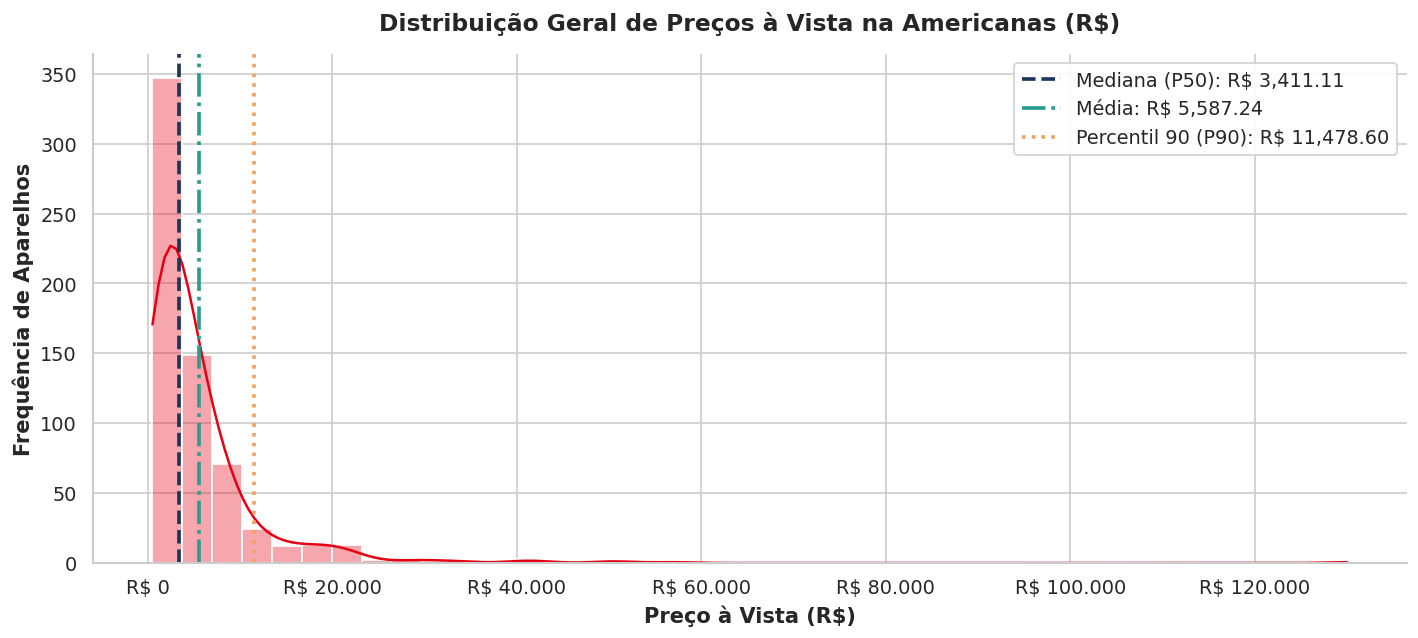

In [6]:
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.histplot(data=df, x='preco_vista', kde=True, bins=40, color='#E60014', alpha=0.35, edgecolor='white', ax=ax)

mediana_geral = df['preco_vista'].median()
media_geral = df['preco_vista'].mean()
p90_geral = df['preco_vista'].quantile(0.90)

ax.axvline(mediana_geral, color='#1B365D', linestyle='--', linewidth=2.2, label=f'Mediana (P50): R$ {mediana_geral:,.2f}')
ax.axvline(media_geral, color='#2A9D8F', linestyle='-.', linewidth=2.2, label=f'Média: R$ {media_geral:,.2f}')
ax.axvline(p90_geral, color='#F4A261', linestyle=':', linewidth=2.2, label=f'Percentil 90 (P90): R$ {p90_geral:,.2f}')

ax.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
ax.set_title('Distribuição Geral de Preços à Vista na Americanas (R$)', fontsize=14, fontweight='bold', pad=14)
ax.set_xlabel('Preço à Vista (R$)')
ax.set_ylabel('Frequência de Aparelhos')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


**Insight de Negócio (Histograma e Densidade):** A distribuição apresenta assimetria positiva pronunciada (a média supera a mediana), mostrando que a maior parte do catálogo está concentrada nas faixas de entrada e intermediária — onde ocorre a disputa por giro — enquanto os 10% mais caros (acima do P90) formam uma cauda longa de alto valor agregado.


### 2.3 Visualização Aprimorada de Outliers e Variância por Categoria (Boxplot Executivo + Stripplot + Escala Log)

Para evitar que valores extremos comprimam a visualização das caixas, construímos um **painel duplo de alta precisão**:
* **Painel Esquerdo (Escala Linear + Pontos Reais + Destaque de Outliers):** Exibe os quartis ($Q1$, Mediana, $Q3$), sobrepõe todos os aparelhos reais (`jitter`) e destaca os **outliers em losangos vermelhos** com anotação direta da mediana de cada categoria.
* **Painel Direito (Escala Logarítmica):** Permite enxergar com nitidez a dispersão interna e a distância relativa dos outliers em categorias de faixas de preço muito diferentes.


=== Diagnóstico Estatístico de Quartis (IQR) e Outliers por Categoria ===


,Categoria,Qtd_Total,Q1_25% (R$),Mediana (R$),Q3_75% (R$),IQR (R$),Limite_Outlier_Sup (R$),Qtd_Outliers,%_Outliers
0,Ar-Condicionados,184,2780.67,3955.50,6208.92,3428.25,11351.30,16,8.7
1,TVs,171,917.62,1449.00,3139.48,2221.86,6472.27,24,14.0
2,Notebooks,92,4067.56,7399.90,18235.00,14167.44,39486.16,3,3.3
3,Celulares e Smartphones,196,1499.00,3299.49,5499.00,4000.00,11499.00,5,2.6


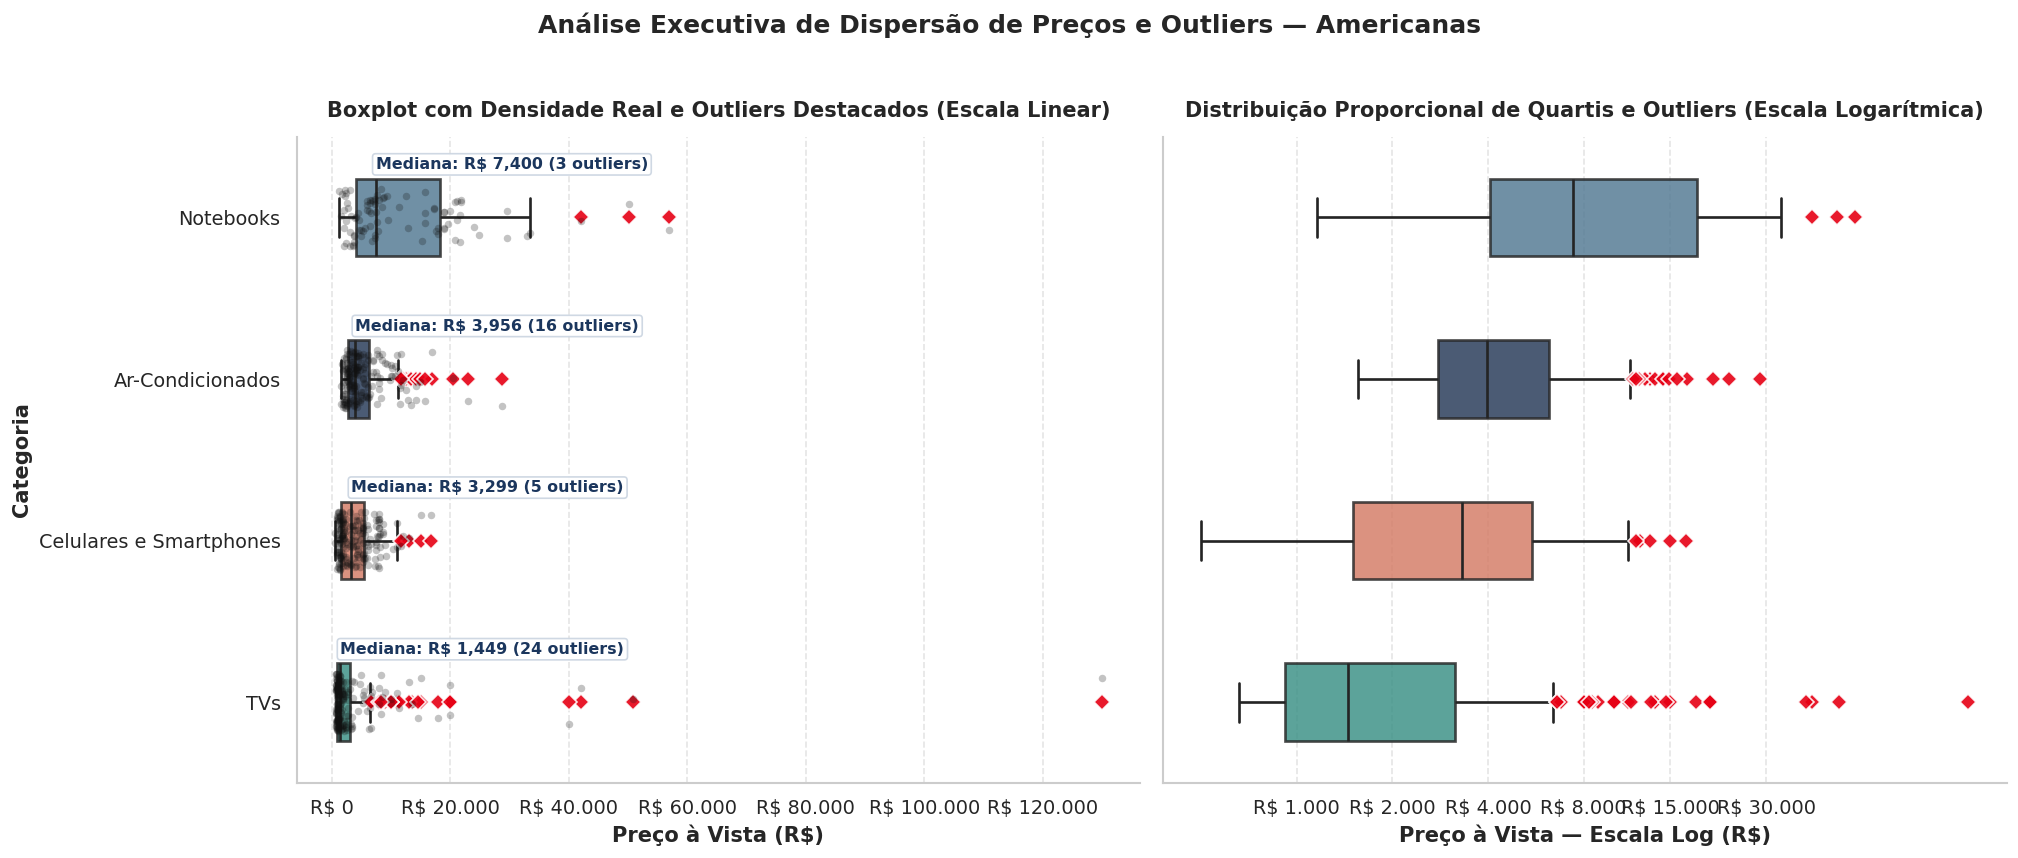

In [7]:
# Cálculo estatístico formal de IQR e Outliers por categoria
diagnostico_outliers = []
for cat in ['Ar-Condicionados', 'TVs', 'Notebooks', 'Celulares e Smartphones']:
    s = df[df['categoria'] == cat]['preco_vista']
    if s.empty:
        continue
    q1 = s.quantile(0.25)
    med = s.median()
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_sup = q3 + 1.5 * iqr
    qtd_out = int((s > lim_sup).sum())
    perc_out = round((qtd_out / len(s)) * 100, 1)
    diagnostico_outliers.append({
        'Categoria': cat,
        'Qtd_Total': len(s),
        'Q1_25% (R$)': round(q1, 2),
        'Mediana (R$)': round(med, 2),
        'Q3_75% (R$)': round(q3, 2),
        'IQR (R$)': round(iqr, 2),
        'Limite_Outlier_Sup (R$)': round(lim_sup, 2),
        'Qtd_Outliers': qtd_out,
        '%_Outliers': perc_out
    })

df_outliers_resumo = pd.DataFrame(diagnostico_outliers)
print("=== Diagnóstico Estatístico de Quartis (IQR) e Outliers por Categoria ===")
display(df_outliers_resumo)

# Visualização Dupla Aprimorada de Outliers
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
ordem_cats = df.groupby('categoria')['preco_vista'].median().sort_values(ascending=False).index.tolist()
paleta_exec = ['#1B365D', '#2A9D8F', '#457B9D', '#E76F51']

flier_estilo = dict(
    marker='D',
    markerfacecolor='#E60014',
    markeredgecolor='white',
    markersize=7,
    alpha=0.9
)

# Painel 1: Boxplot Horizontal + Stripplot + Rótulos de Mediana
sns.boxplot(
    data=df, y='categoria', x='preco_vista', order=ordem_cats,
    palette=paleta_exec, hue='categoria', legend=False,
    width=0.48, linewidth=1.6, flierprops=flier_estilo,
    boxprops=dict(alpha=0.82), ax=axes[0]
)
sns.stripplot(
    data=df, y='categoria', x='preco_vista', order=ordem_cats,
    color='#111111', alpha=0.25, size=4.5, jitter=0.18, ax=axes[0]
)

for idx, cat in enumerate(ordem_cats):
    sub_s = df[df['categoria'] == cat]['preco_vista']
    med_v = sub_s.median()
    q3_v = sub_s.quantile(0.75)
    lim_v = q3_v + 1.5 * (q3_v - sub_s.quantile(0.25))
    qtd_o = int((sub_s > lim_v).sum())
    axes[0].text(
        med_v, idx - 0.30,
        f"Mediana: R$ {med_v:,.0f} ({qtd_o} outliers)",
        color='#1B365D', fontweight='bold', fontsize=9.5,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#CBD5E1', alpha=0.92)
    )

axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
axes[0].set_title('Boxplot com Densidade Real e Outliers Destacados (Escala Linear)', fontsize=12.5, fontweight='bold', pad=12)
axes[0].set_xlabel('Preço à Vista (R$)')
axes[0].set_ylabel('Categoria')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Painel 2: Boxplot em Escala Logarítmica (visão sem distorção de extremos)
sns.boxplot(
    data=df, y='categoria', x='preco_vista', order=ordem_cats,
    palette=paleta_exec, hue='categoria', legend=False,
    width=0.48, linewidth=1.6, flierprops=flier_estilo,
    boxprops=dict(alpha=0.82), ax=axes[1]
)
axes[1].set_xscale('log')
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
axes[1].set_xticks([1000, 2000, 4000, 8000, 15000, 30000])
axes[1].set_title('Distribuição Proporcional de Quartis e Outliers (Escala Logarítmica)', fontsize=12.5, fontweight='bold', pad=12)
axes[1].set_xlabel('Preço à Vista — Escala Log (R$)')
axes[1].set_ylabel('')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle('Análise Executiva de Dispersão de Preços e Outliers — Americanas', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Insight de Negócio (Boxplot e Outliers):** Os losangos vermelhos identificam exatamente os anúncios acima do limite superior interquartil ($Q3 + 1,5 \times IQR$). Em categorias como **Notebooks** e **TVs**, esses *outliers* correspondem a linhas gamer/profissionais e telas de grande porte (65" a 85"), que não devem ser misturados aos itens de entrada na hora de calcular metas de margem ou promoções.


### 2.4 Variáveis Categóricas: Top Lojas (Sellers), Top Marcas e Preço Mediano por Especificação


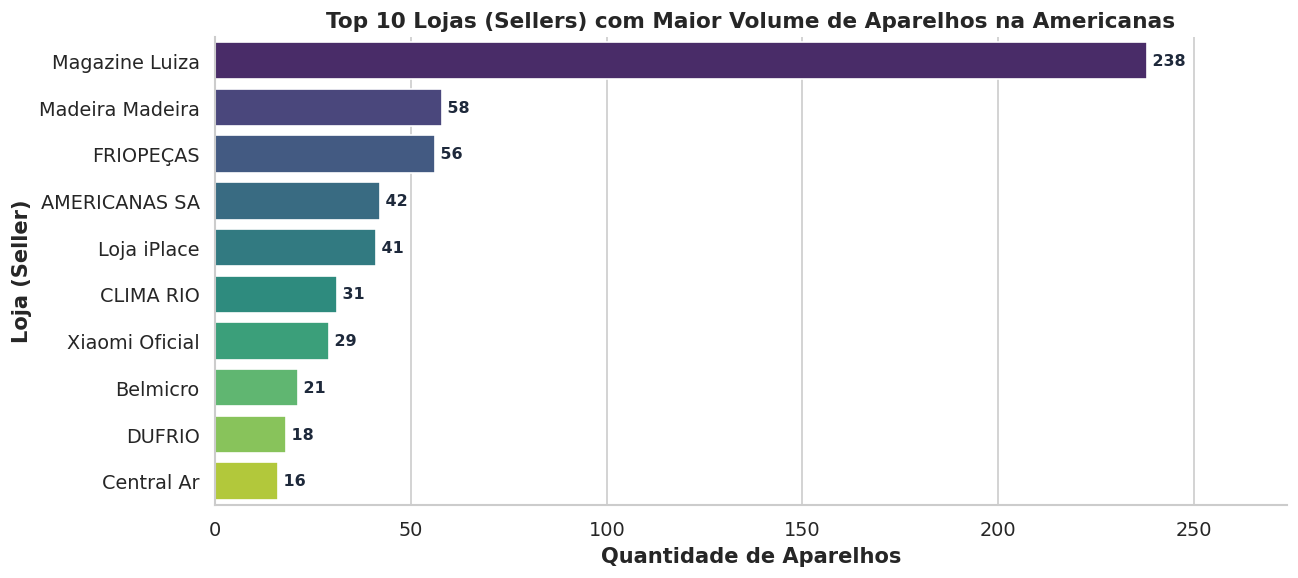

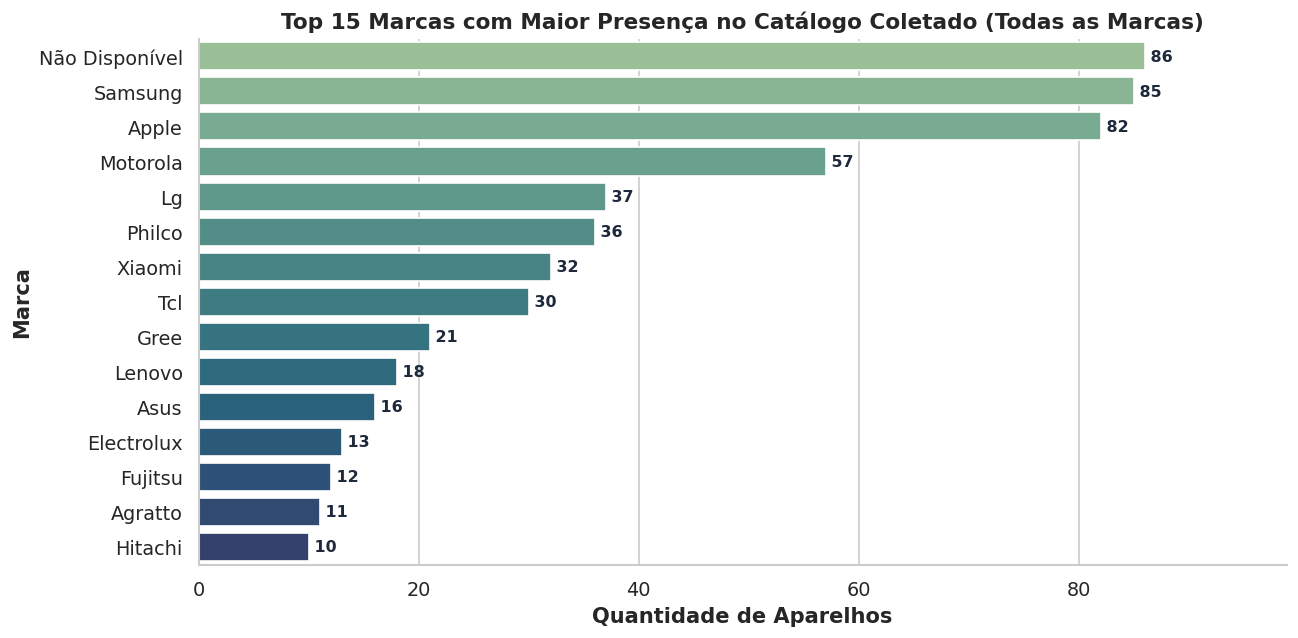

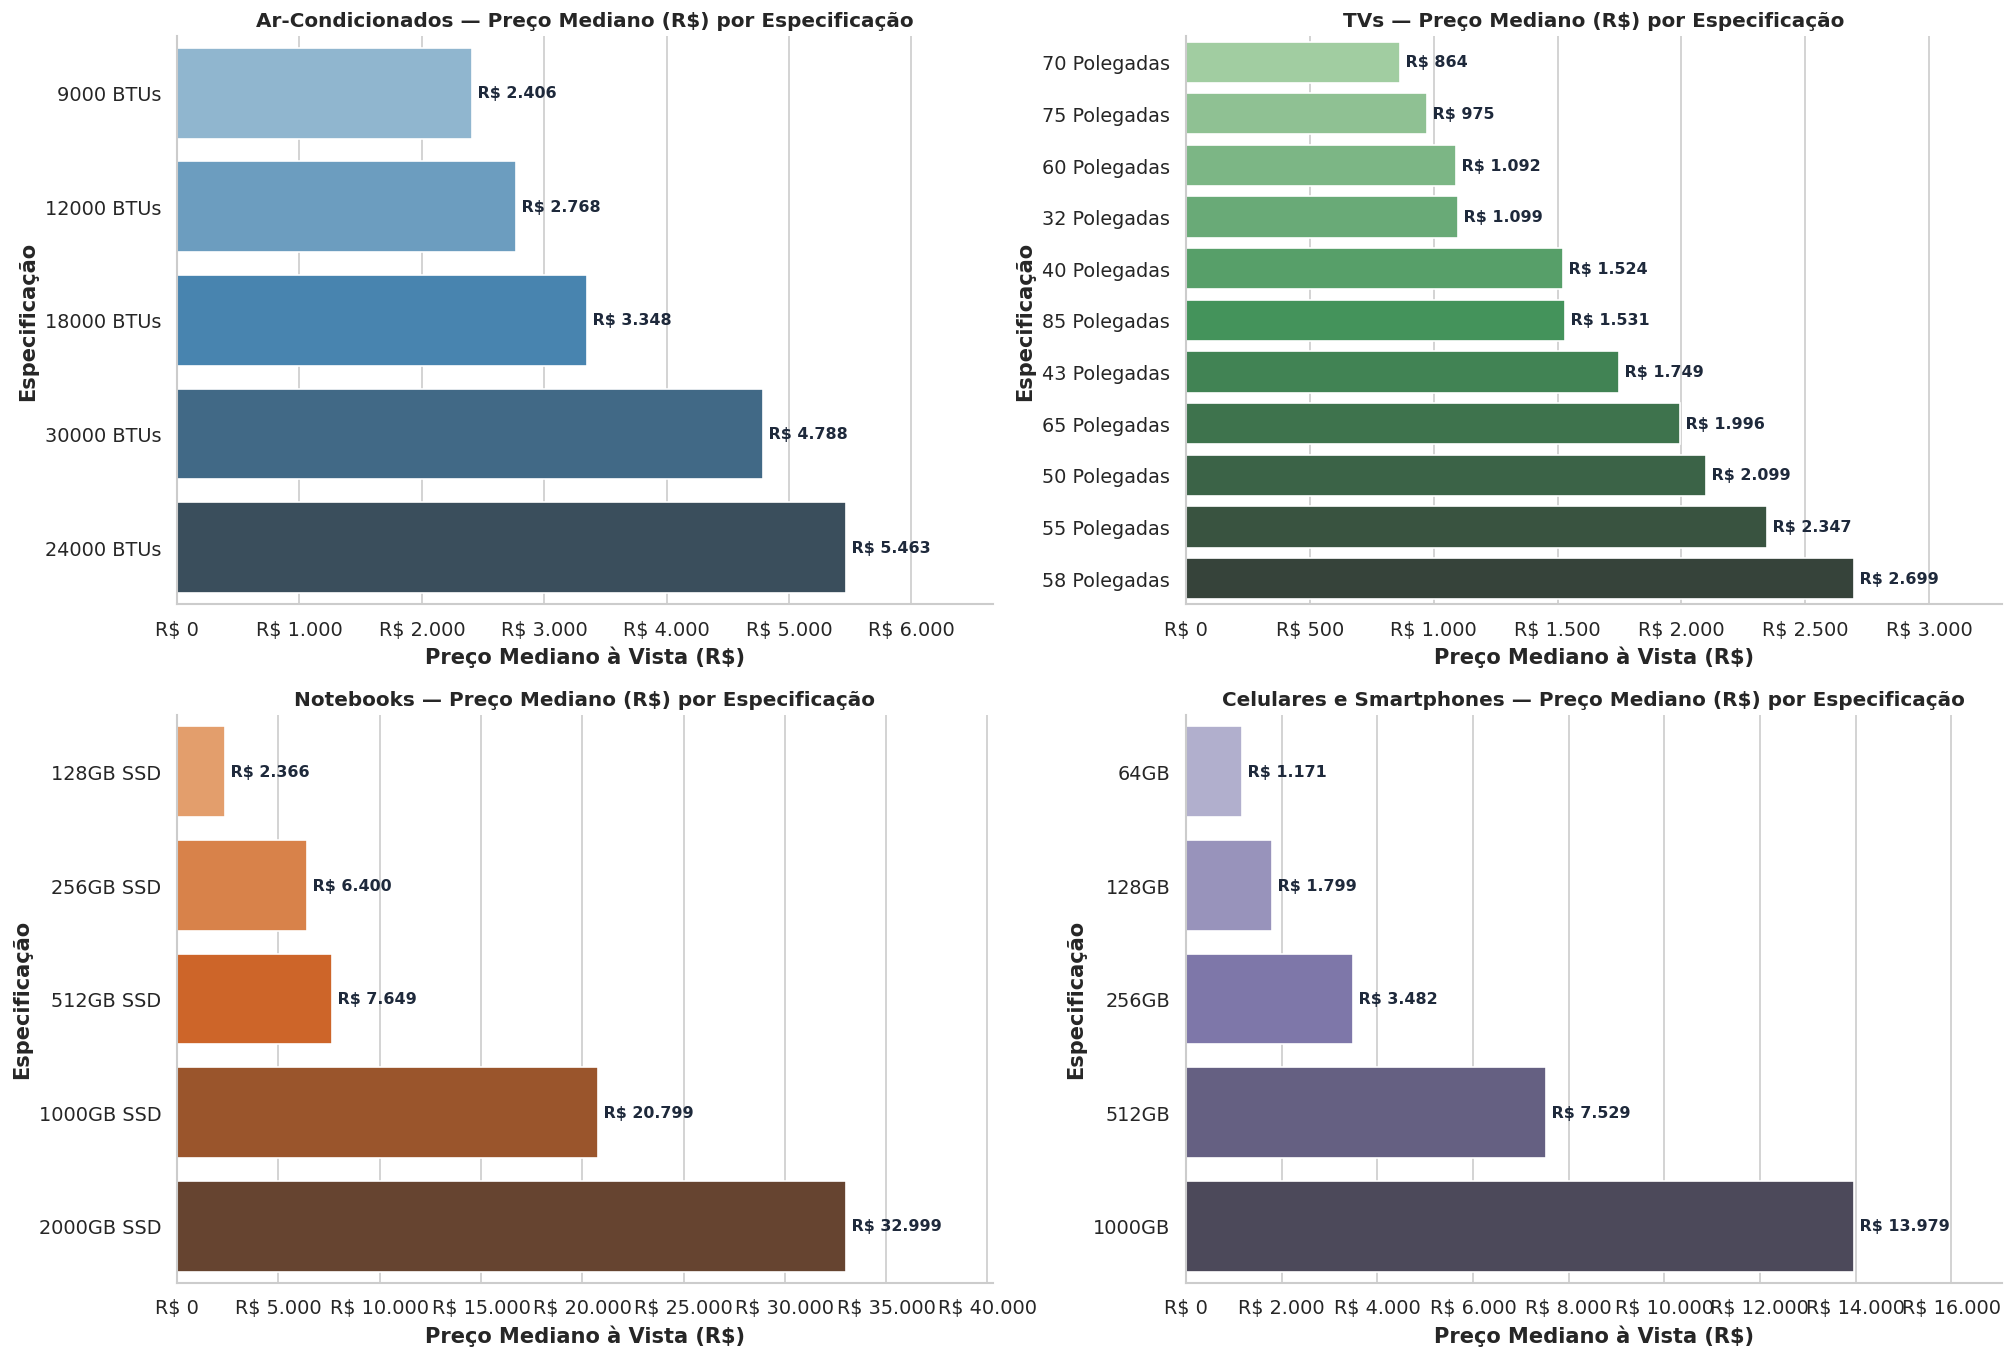

In [8]:
def adicionar_rotulos_barras(ax, formato='int'):
    for p in ax.patches:
        largura = p.get_width()
        if largura > 0:
            txt = f" {int(largura)}" if formato == 'int' else f" R$ {largura:,.0f}".replace(",", ".")
            ax.text(
                largura, p.get_y() + p.get_height() / 2,
                txt, va='center', ha='left', fontsize=9.5, fontweight='bold', color='#1E293B'
            )

# Gráfico 1: Top 10 Lojas (Sellers) na Americanas
top_lojas = df['loja'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=top_lojas.values, y=top_lojas.index, hue=top_lojas.index, palette='viridis', legend=False, ax=ax)
adicionar_rotulos_barras(ax, 'int')
ax.set_xlim(0, top_lojas.values.max() * 1.15)
ax.set_title('Top 10 Lojas (Sellers) com Maior Volume de Aparelhos na Americanas', fontsize=13, fontweight='bold')
ax.set_xlabel('Quantidade de Aparelhos')
ax.set_ylabel('Loja (Seller)')
plt.tight_layout()
plt.show()

# Gráfico 2: Top 15 Marcas Capturadas do Site
top_marcas = df['marca'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(x=top_marcas.values, y=top_marcas.index, hue=top_marcas.index, palette='crest', legend=False, ax=ax)
adicionar_rotulos_barras(ax, 'int')
ax.set_xlim(0, top_marcas.values.max() * 1.15)
ax.set_title('Top 15 Marcas com Maior Presença no Catálogo Coletado (Todas as Marcas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Quantidade de Aparelhos')
ax.set_ylabel('Marca')
plt.tight_layout()
plt.show()

# Gráfico 3: Painel 2x2 — Preço Mediano por Especificação Técnica em Cada Categoria
fig, axes = plt.subplots(2, 2, figsize=(17, 11.5))
axes = axes.flatten()
categorias_ordem = ['Ar-Condicionados', 'TVs', 'Notebooks', 'Celulares e Smartphones']
paletas = ['Blues_d', 'Greens_d', 'Oranges_d', 'Purples_d']

for idx, cat in enumerate(categorias_ordem):
    ax = axes[idx]
    sub = df[(df['categoria'] == cat) & (df['especificacao_tecnica'] != 'Não Especificado')]
    if not sub.empty:
        resumo_spec = sub.groupby('especificacao_tecnica')['preco_vista'].median().sort_values(ascending=True)
        sns.barplot(x=resumo_spec.values, y=resumo_spec.index, hue=resumo_spec.index, palette=paletas[idx], legend=False, ax=ax)
        adicionar_rotulos_barras(ax, 'moeda')
        ax.set_xlim(0, resumo_spec.values.max() * 1.22)
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
        ax.set_title(f'{cat} — Preço Mediano (R$) por Especificação', fontsize=12, fontweight='bold')
        ax.set_xlabel('Preço Mediano à Vista (R$)')
        ax.set_ylabel('Especificação')

plt.tight_layout()
plt.show()


**Insights de Negócio (Lojas, Marcas e Especificações):**
* **Sellers e Marcas:** Os gráficos quantificam a concentração de ofertas entre a operação própria da Americanas e lojistas parceiros, bem como a liderança das principais fabricantes em cada vitrine.
* **Escada de Valor por Especificação:** O painel 2×2 demonstra o salto direto de preço mediano à medida que a especificação técnica aumenta (BTUs em Ar-Condicionados, Polegadas em TVs e Capacidade GB/SSD em Notebooks e Smartphones).


---
## Etapa 3: Normalização e Modelagem Preditiva — Regressão Linear de TODAS as Categorias (Peso: 1,5 pontos)

### Metodologia de Pré-processamento
* **Prevenção de *Data Leakage*:** Excluímos `preco_total`, `valor_parcela` e `total_parcelado` das variáveis preditoras por serem derivadas diretamente da variável alvo `preco_vista`.
* **Encoding:** Aplicamos **One-Hot Encoding** (`pd.get_dummies`) em todas as variáveis categóricas (`marca`, `modelo`, `especificacao_tecnica`, `memoria_ram`, `atributo_extra_1`, `atributo_extra_2`, `voltagem`, `tem_juros`, `seller_terceiro` e `loja`).
* **Justificativa da Normalização (`RobustScaler`):** Escolhemos o **`RobustScaler`** em vez de `MinMaxScaler` ou `StandardScaler` porque dados de e-commerce possuem *outliers* significativos (comprovados nos boxplots da Etapa 2). Como o `RobustScaler` utiliza a mediana e o intervalo interquartil (IQR), ele não sofre distorção por itens de valor extremo. O `.fit()` é aplicado **exclusivamente nos dados de treino** após o *split* `80/20` (`random_state=42`).

### 3.1 Regressão Linear Individual para CADA uma das 4 Categorias


In [9]:
features_num_cat = ['qtd_parcelas', 'desconto_perc', 'qtd_especificacoes_site']
features_cat_base = [
    'marca', 'modelo', 'especificacao_tecnica', 'memoria_ram',
    'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'tem_juros', 'seller_terceiro'
]

resultados_reg_linear_categorias = []
dados_graficos_cat = {}

for cat in ['Celulares e Smartphones', 'TVs', 'Notebooks', 'Ar-Condicionados']:
    sub = df[df['categoria'] == cat].copy()
    if len(sub) < 10:
        print(f"⚠️ Categoria '{cat}' possui poucos registros ({len(sub)}) para split treino/teste.")
        continue

    top_lojas_cat = sub['loja'].value_counts().head(10).index
    sub['loja_agrupada'] = sub['loja'].where(sub['loja'].isin(top_lojas_cat), 'Outras')
    cols_cat = features_cat_base + ['loja_agrupada']

    X_cat = sub[features_num_cat + cols_cat].copy()
    y_cat = sub['preco_vista'].copy()

    # 1. One-Hot Encoding
    X_cat_enc = pd.get_dummies(X_cat, columns=cols_cat, drop_first=True)

    # 2. Train/Test Split (80/20 com random_state=42)
    X_tr, X_te, y_tr, y_te = train_test_split(X_cat_enc, y_cat, test_size=0.20, random_state=42)

    # 3. Escalonamento com RobustScaler (fit APENAS no treino)
    scaler_cat = RobustScaler()
    X_tr[features_num_cat] = scaler_cat.fit_transform(X_tr[features_num_cat])
    X_te[features_num_cat] = scaler_cat.transform(X_te[features_num_cat])

    # 4. Treinamento da Regressão Linear específica da categoria
    lr_cat = LinearRegression()
    lr_cat.fit(X_tr, y_tr)
    y_pred_cat = np.maximum(lr_cat.predict(X_te), 0)

    # 5. Métricas obrigatórias nos dados de teste (MAE, RMSE e R²)
    mae_c = mean_absolute_error(y_te, y_pred_cat)
    rmse_c = np.sqrt(mean_squared_error(y_te, y_pred_cat))
    r2_c = r2_score(y_te, y_pred_cat)

    resultados_reg_linear_categorias.append({
        'Categoria': cat,
        'Amostras_Total': len(sub),
        'Amostras_Teste': len(y_te),
        'MAE (R$)': round(mae_c, 2),
        'RMSE (R$)': round(rmse_c, 2),
        'R²': round(r2_c, 4),
        'Preco_Medio_Real (R$)': round(y_te.mean(), 2)
    })

    dados_graficos_cat[cat] = (y_te, y_pred_cat, mae_c, rmse_c, r2_c)

df_resumo_lr_cats = pd.DataFrame(resultados_reg_linear_categorias)
print("=== Performance das Regressões Lineares por Categoria (Dados de Teste) ===")
display(df_resumo_lr_cats)

for row in resultados_reg_linear_categorias:
    print(
        f"• {row['Categoria']}: a Regressão Linear erra o preço à vista, em média, em R$ {row['MAE (R$)']:,.2f} (MAE), "
        f"com RMSE de R$ {row['RMSE (R$)']:,.2f} e R² = {row['R²']:.4f}."
    )


=== Performance das Regressões Lineares por Categoria (Dados de Teste) ===


,Categoria,Amostras_Total,Amostras_Teste,MAE (R$),RMSE (R$),R²,Preco_Medio_Real (R$)
0,Celulares e Smartphones,196,40,564.54,958.68,0.8929,4098.24
1,TVs,171,35,2159.28,4115.33,0.7861,4415.41
2,Notebooks,92,19,6990.67,10574.80,-0.4056,9740.28
3,Ar-Condicionados,184,37,2948.37,5063.90,-0.1433,5882.90


• Celulares e Smartphones: a Regressão Linear erra o preço à vista, em média, em R$ 564.54 (MAE), com RMSE de R$ 958.68 e R² = 0.8929.
• TVs: a Regressão Linear erra o preço à vista, em média, em R$ 2,159.28 (MAE), com RMSE de R$ 4,115.33 e R² = 0.7861.
• Notebooks: a Regressão Linear erra o preço à vista, em média, em R$ 6,990.67 (MAE), com RMSE de R$ 10,574.80 e R² = -0.4056.
• Ar-Condicionados: a Regressão Linear erra o preço à vista, em média, em R$ 2,948.37 (MAE), com RMSE de R$ 5,063.90 e R² = -0.1433.


### 3.2 Visualização das Regressões Lineares por Categoria (Real vs. Previsto — Painel 2×2)


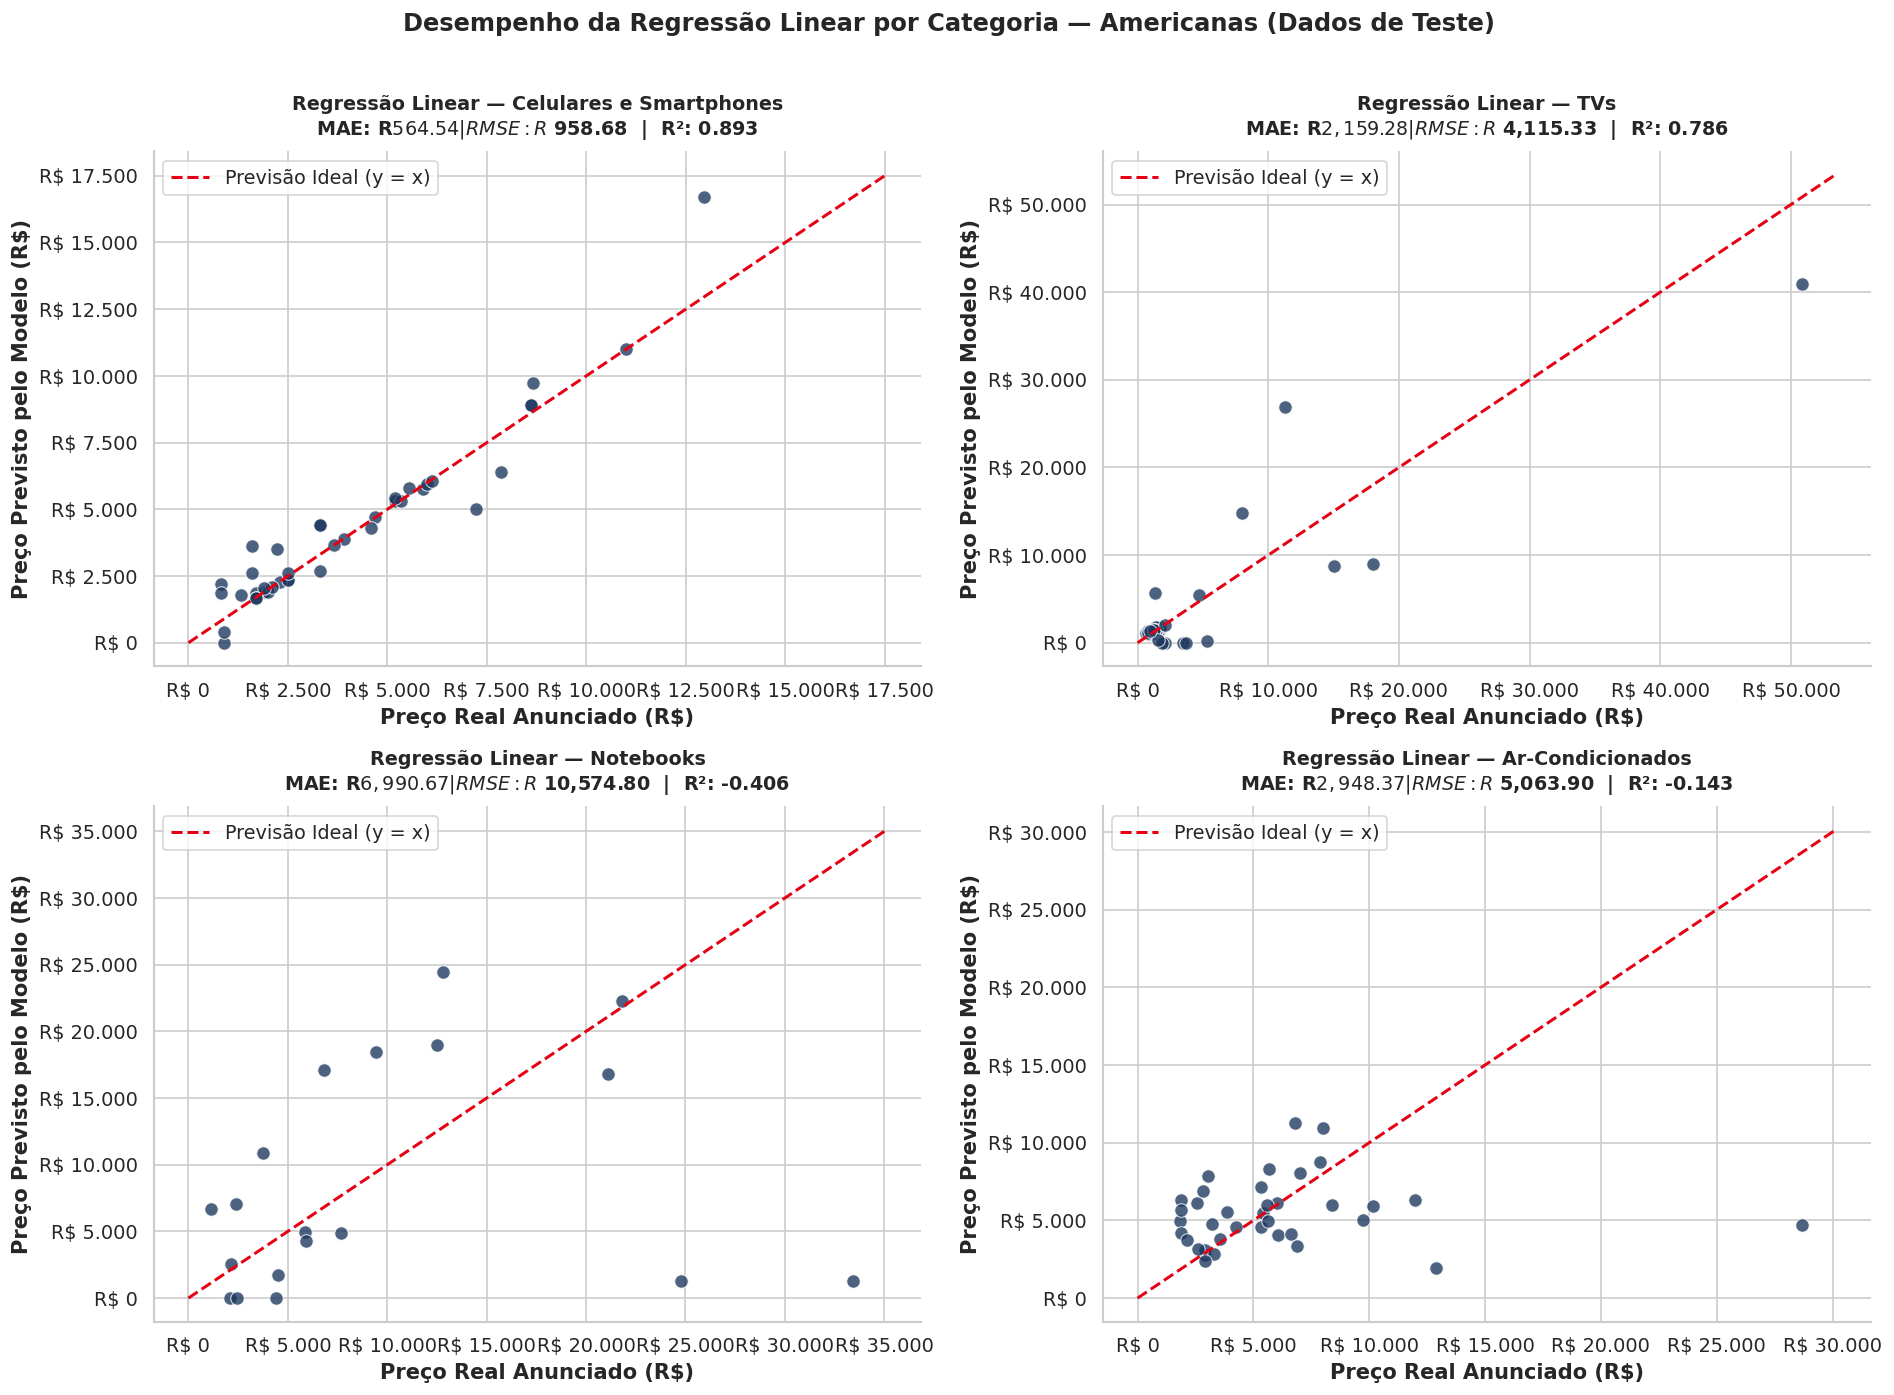

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11.5))
axes = axes.flatten()

for idx, (cat, (y_te, y_pr, mae_c, rmse_c, r2_c)) in enumerate(dados_graficos_cat.items()):
    ax = axes[idx]
    sns.scatterplot(x=y_te, y=y_pr, alpha=0.78, s=65, color='#1B365D', edgecolor='white', ax=ax)
    lim_max = max(y_te.max(), y_pr.max()) * 1.05
    ax.plot([0, lim_max], [0, lim_max], color='#E60014', linestyle='--', linewidth=1.8, label='Previsão Ideal (y = x)')
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax.set_title(
        f'Regressão Linear — {cat}\nMAE: R$ {mae_c:,.2f}  |  RMSE: R$ {rmse_c:,.2f}  |  R²: {r2_c:.3f}',
        fontsize=11.5, fontweight='bold', pad=10
    )
    ax.set_xlabel('Preço Real Anunciado (R$)')
    ax.set_ylabel('Preço Previsto pelo Modelo (R$)')
    ax.legend(loc='upper left', frameon=True, facecolor='white')

plt.suptitle('Desempenho da Regressão Linear por Categoria — Americanas (Dados de Teste)', fontsize=14.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 3.3 Benchmark Automatizado Multi-Algoritmo (Base Consolidada): 5 Modelos em Laço de Repetição

Nesta etapa, implementamos uma estrutura de repetição (`for`) que percorre automaticamente os **5 algoritmos de regressão** exigidos:
1. **Regressão Linear** (`LinearRegression`)
2. **Árvore de Decisão** (`DecisionTreeRegressor`)
3. **K-Nearest Neighbors** (`KNeighborsRegressor`)
4. **Random Forest Regressor** (`RandomForestRegressor`)
5. **Gradient Boosting Regressor** (`GradientBoostingRegressor`)

Para **cada um dos 5 algoritmos**, o laço executa obrigatoriamente:
* **Treinamento** com `X_train` e `y_train`;
* **Predição** sobre `X_test`;
* **Cálculo e impressão das 4 métricas de negócio:** **MAE**, **RMSE**, **MAPE (%)** e **R²**;
* **Painel 2×2 com os 4 gráficos individuais daquele modelo:**
  1. **Dispersão do R²** (Preço Real vs. Preço Previsto com reta ideal $y = x$);
  2. **Barras do MAE** (Erro Médio Absoluto em R$ por Categoria);
  3. **Histograma do MAPE (%)** (Distribuição do Erro Percentual Absoluto por anúncio);
  4. **Dispersão do RMSE** (Resíduos Quadráticos / Raiz do Erro por Faixa de Preço).


🚀 EXECUTANDO ALGORITMO: REGRESSÃO LINEAR
📊 Métricas de Negócio (Regressão Linear):
   • MAE  (Erro Médio Absoluto):            R$ 2,889.45
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 5,830.16
   • MAPE (Erro Percentual Médio Absoluto): 75.62%
   • R²   (Coeficiente de Determinação):    0.3974 (39.74% de variância explicada)


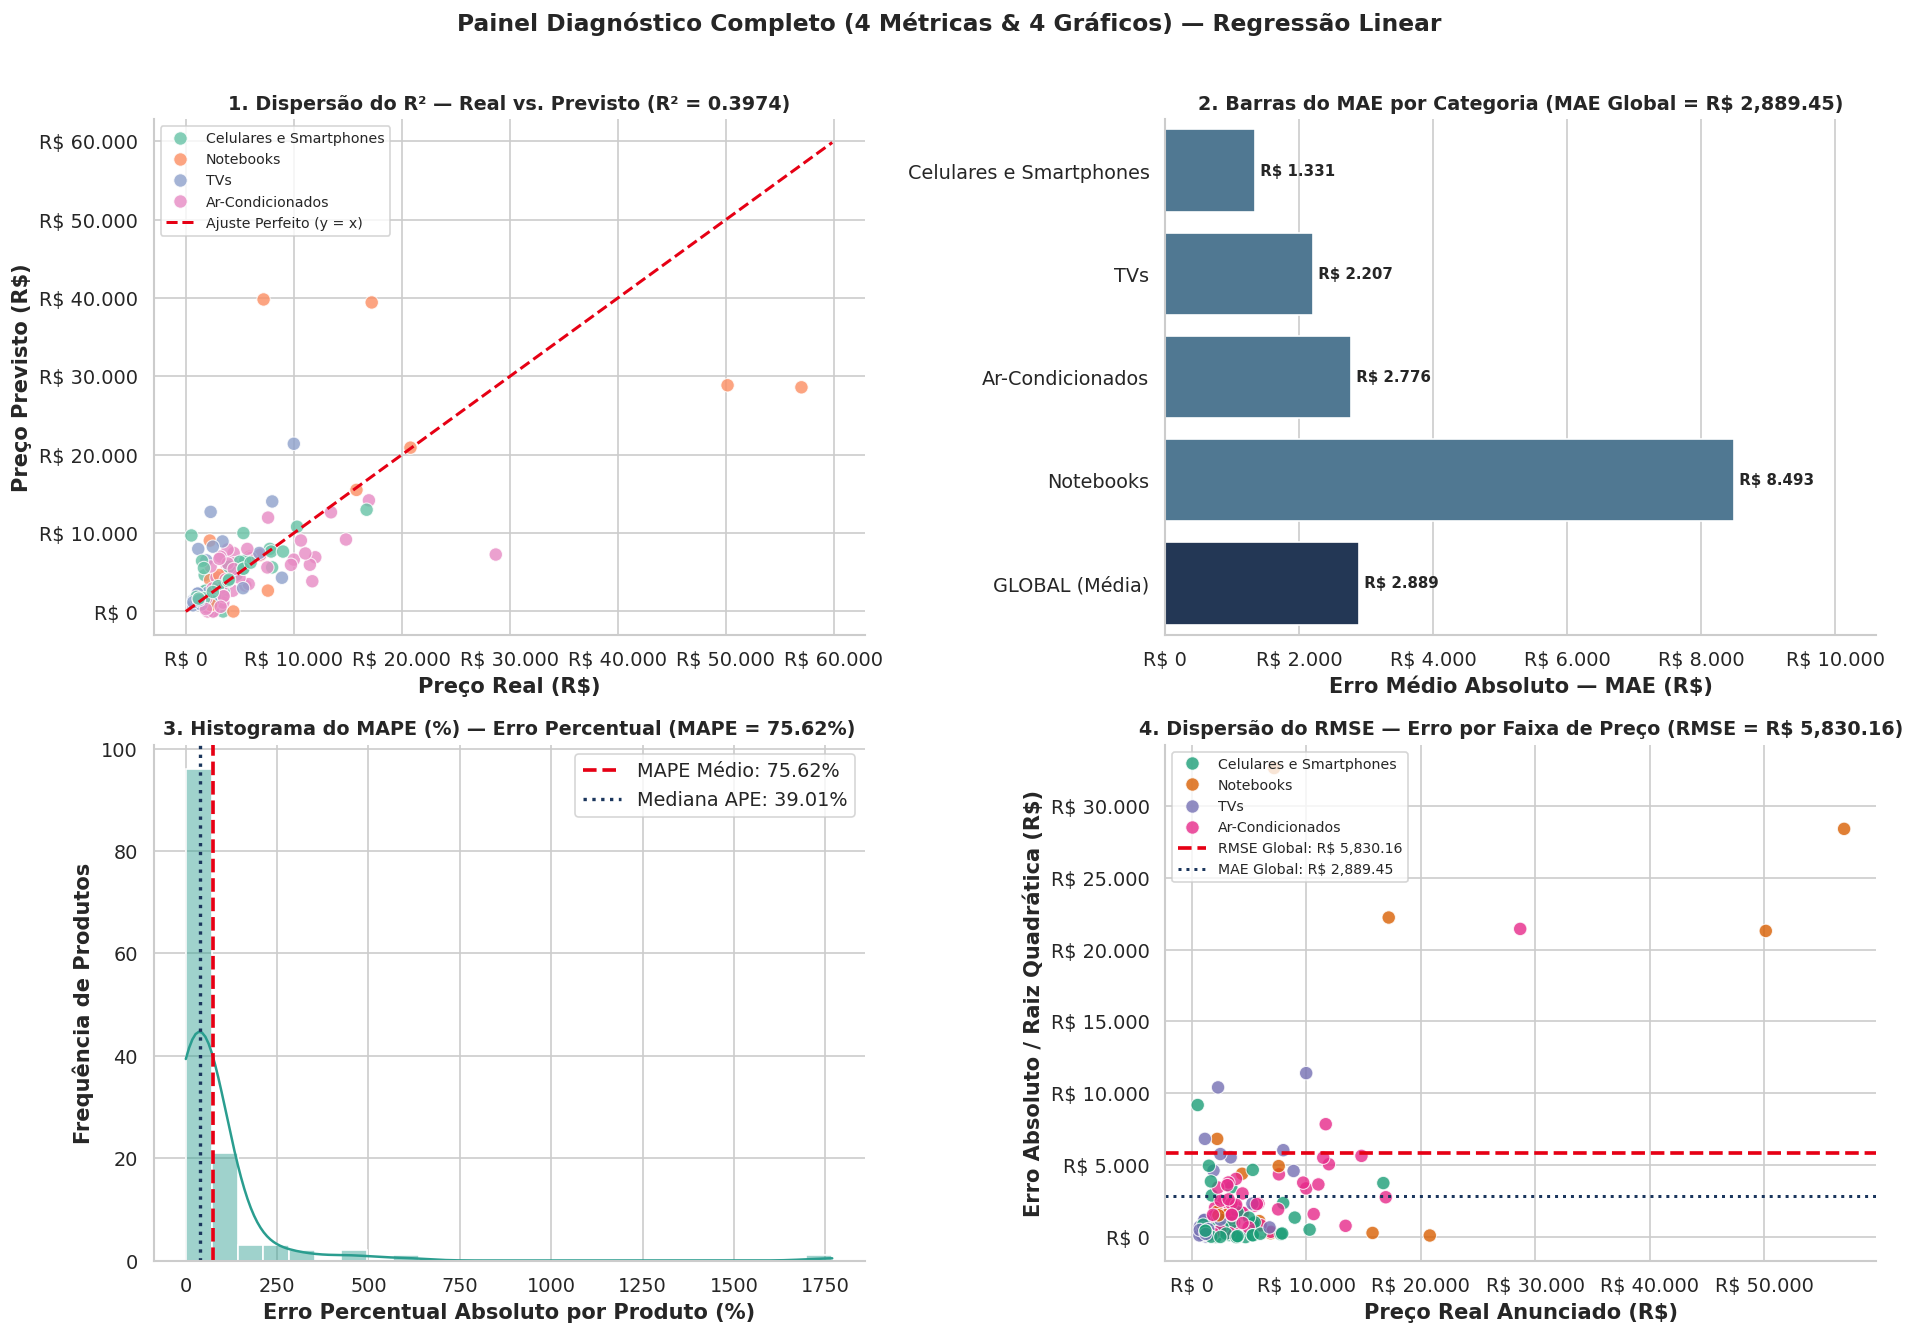

🚀 EXECUTANDO ALGORITMO: ÁRVORE DE DECISÃO
📊 Métricas de Negócio (Árvore de Decisão):
   • MAE  (Erro Médio Absoluto):            R$ 1,840.04
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 4,211.56
   • MAPE (Erro Percentual Médio Absoluto): 26.65%
   • R²   (Coeficiente de Determinação):    0.6855 (68.55% de variância explicada)


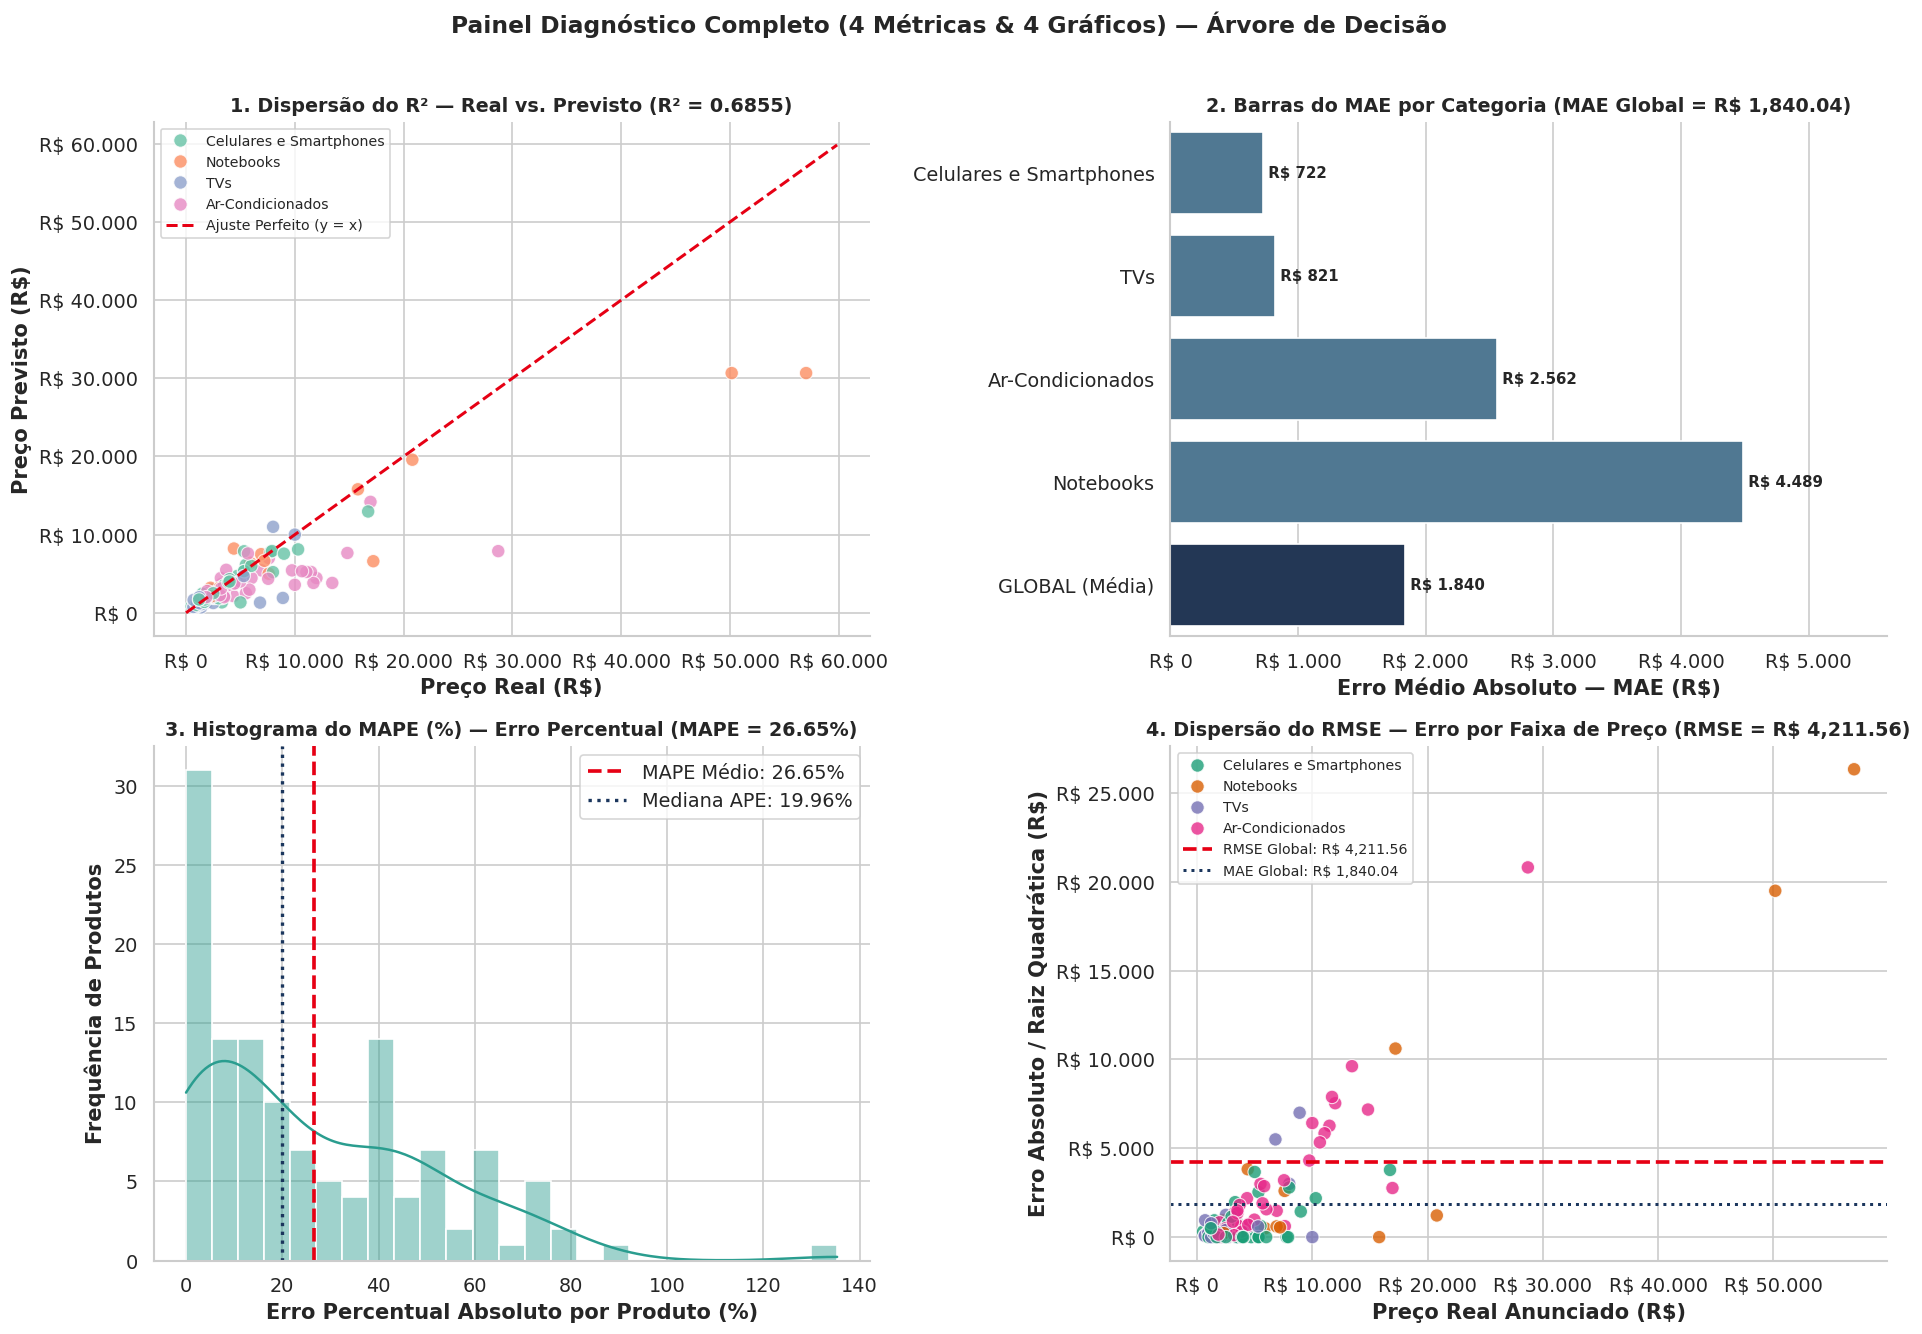

🚀 EXECUTANDO ALGORITMO: KNEIGHBORSREGRESSOR
📊 Métricas de Negócio (KNeighborsRegressor):
   • MAE  (Erro Médio Absoluto):            R$ 1,918.76
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 4,491.34
   • MAPE (Erro Percentual Médio Absoluto): 34.52%
   • R²   (Coeficiente de Determinação):    0.6424 (64.24% de variância explicada)


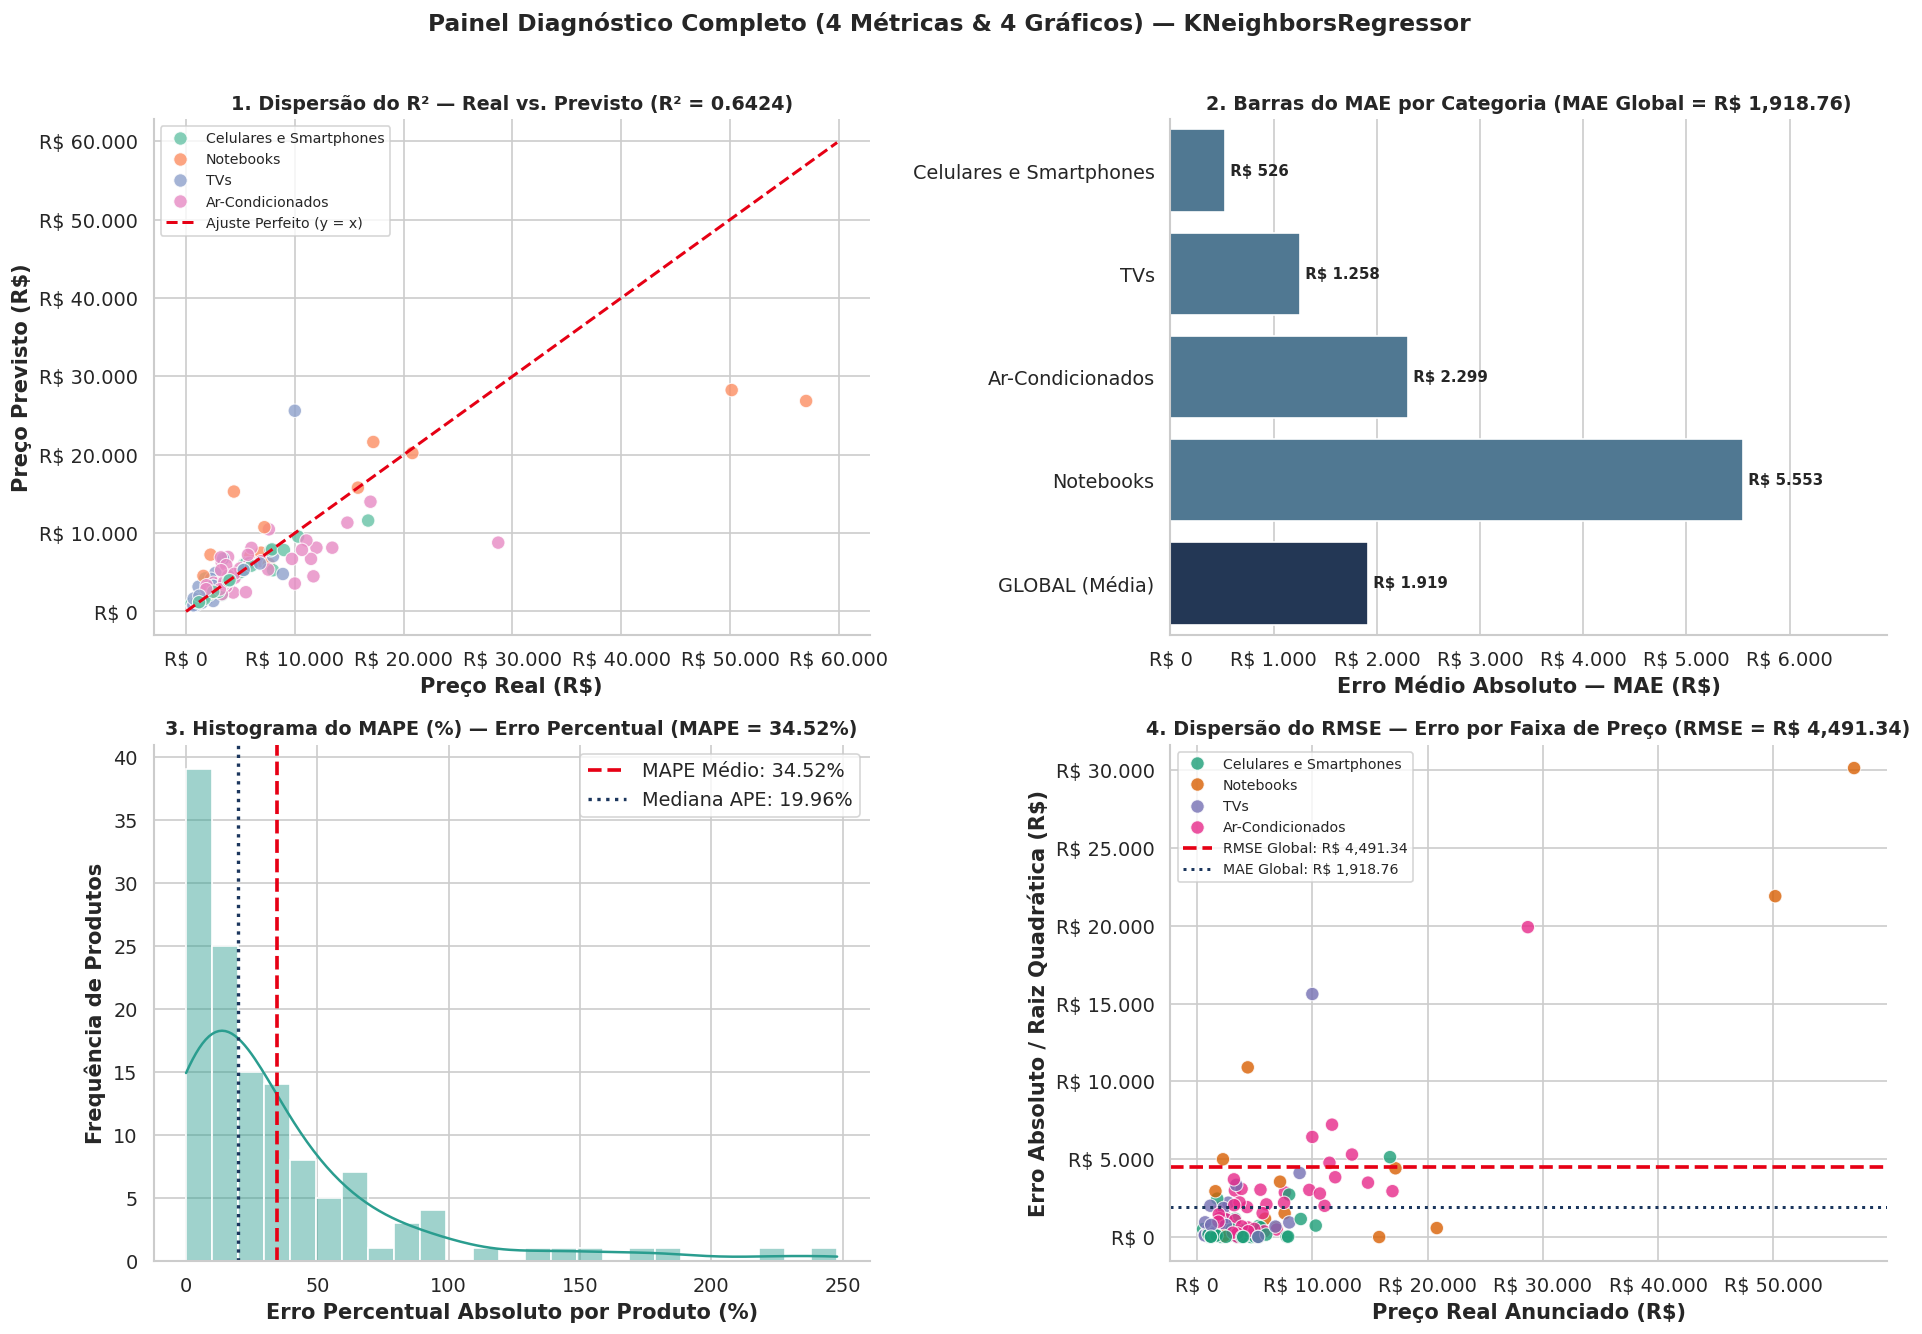

🚀 EXECUTANDO ALGORITMO: RANDOMFORESTREGRESSOR
📊 Métricas de Negócio (RandomForestRegressor):
   • MAE  (Erro Médio Absoluto):            R$ 1,934.76
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 4,819.82
   • MAPE (Erro Percentual Médio Absoluto): 32.48%
   • R²   (Coeficiente de Determinação):    0.5881 (58.81% de variância explicada)


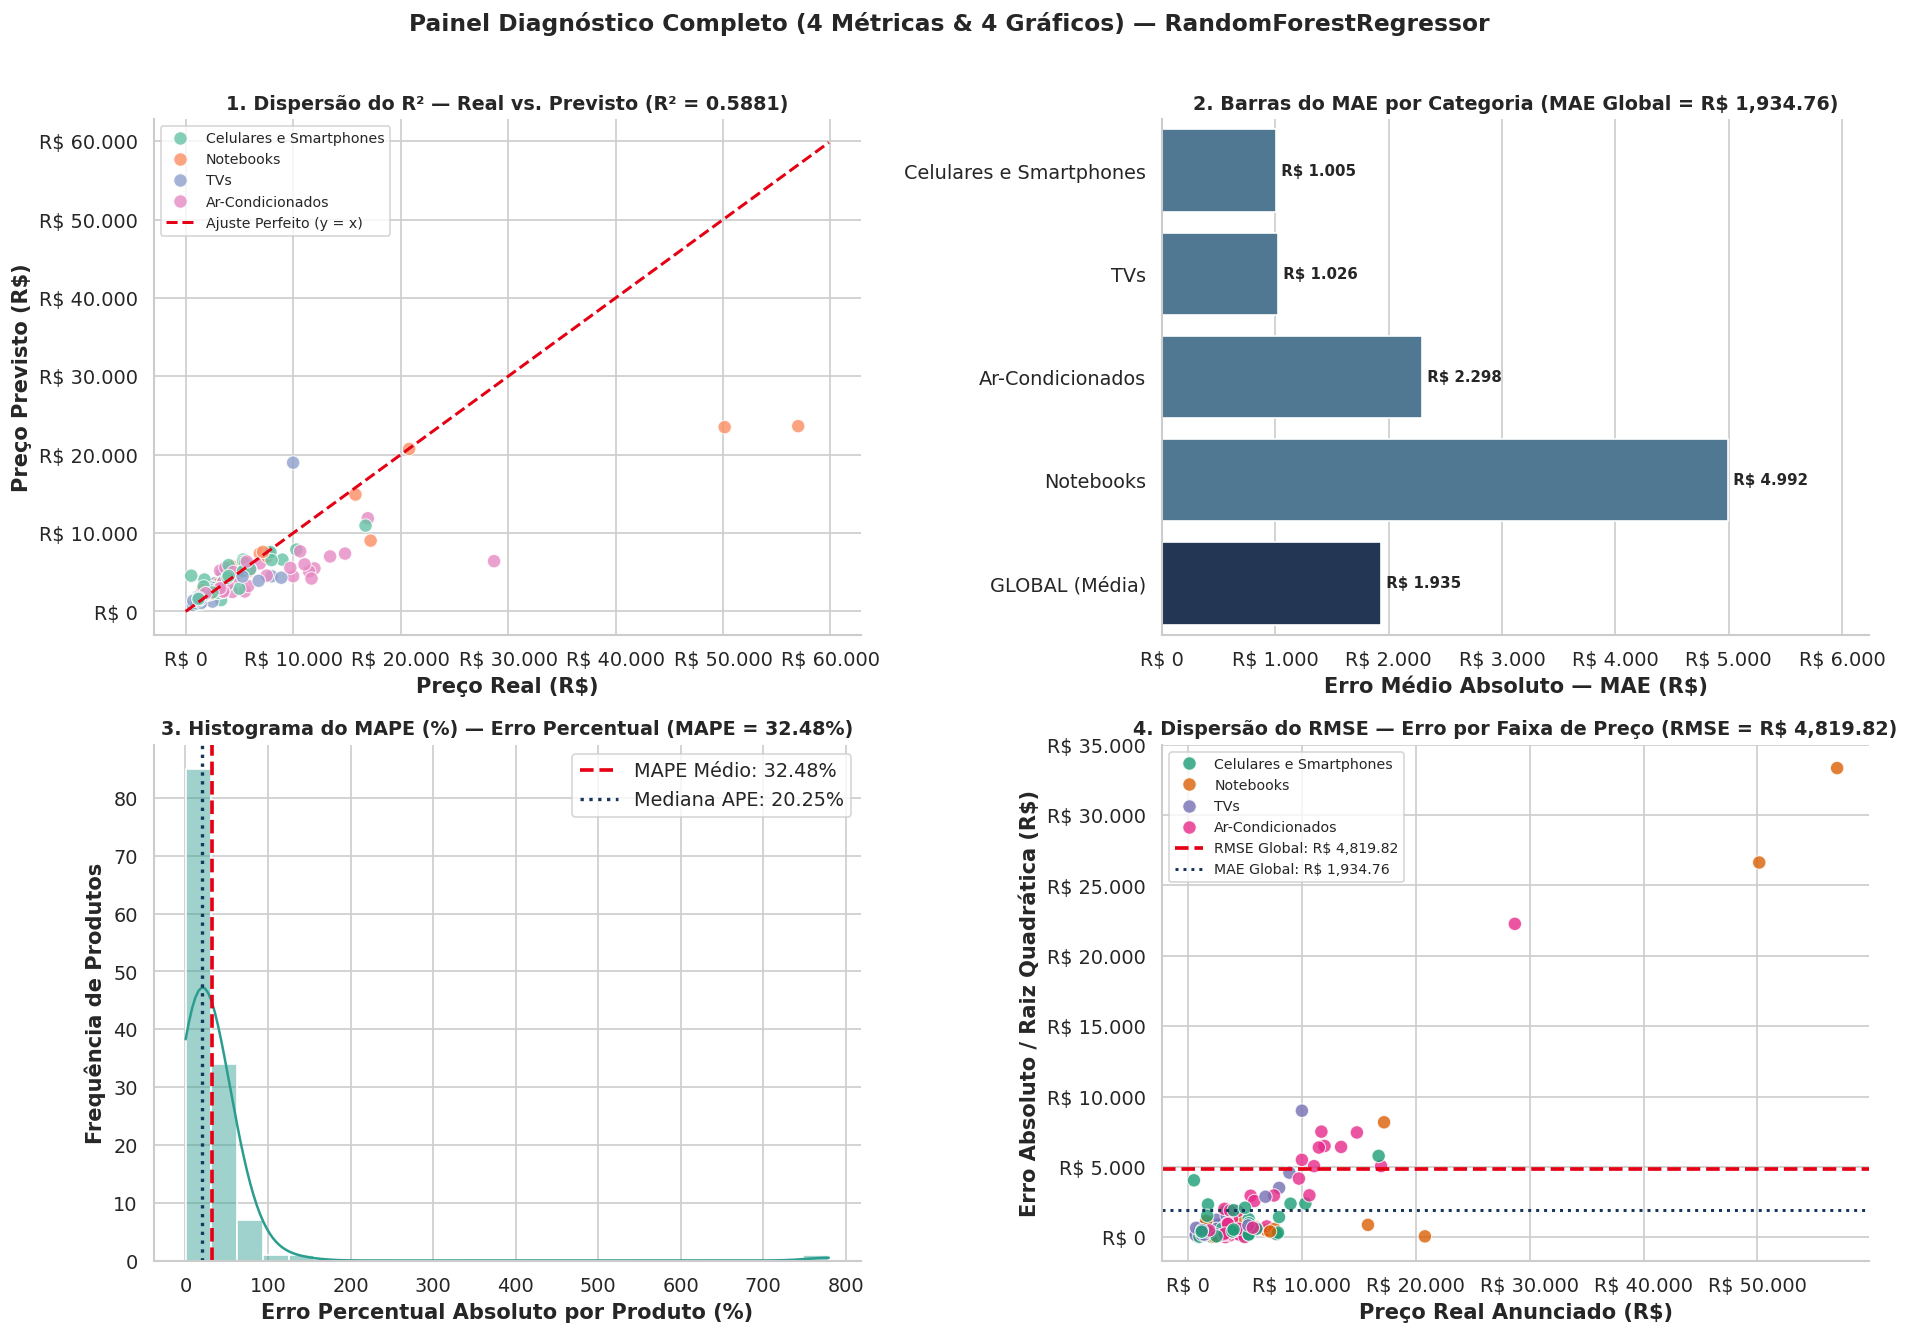

🚀 EXECUTANDO ALGORITMO: GRADIENTBOOSTINGREGRESSOR
📊 Métricas de Negócio (GradientBoostingRegressor):
   • MAE  (Erro Médio Absoluto):            R$ 2,170.29
   • RMSE (Raiz do Erro Quadrático Médio):  R$ 4,616.72
   • MAPE (Erro Percentual Médio Absoluto): 42.41%
   • R²   (Coeficiente de Determinação):    0.6221 (62.21% de variância explicada)


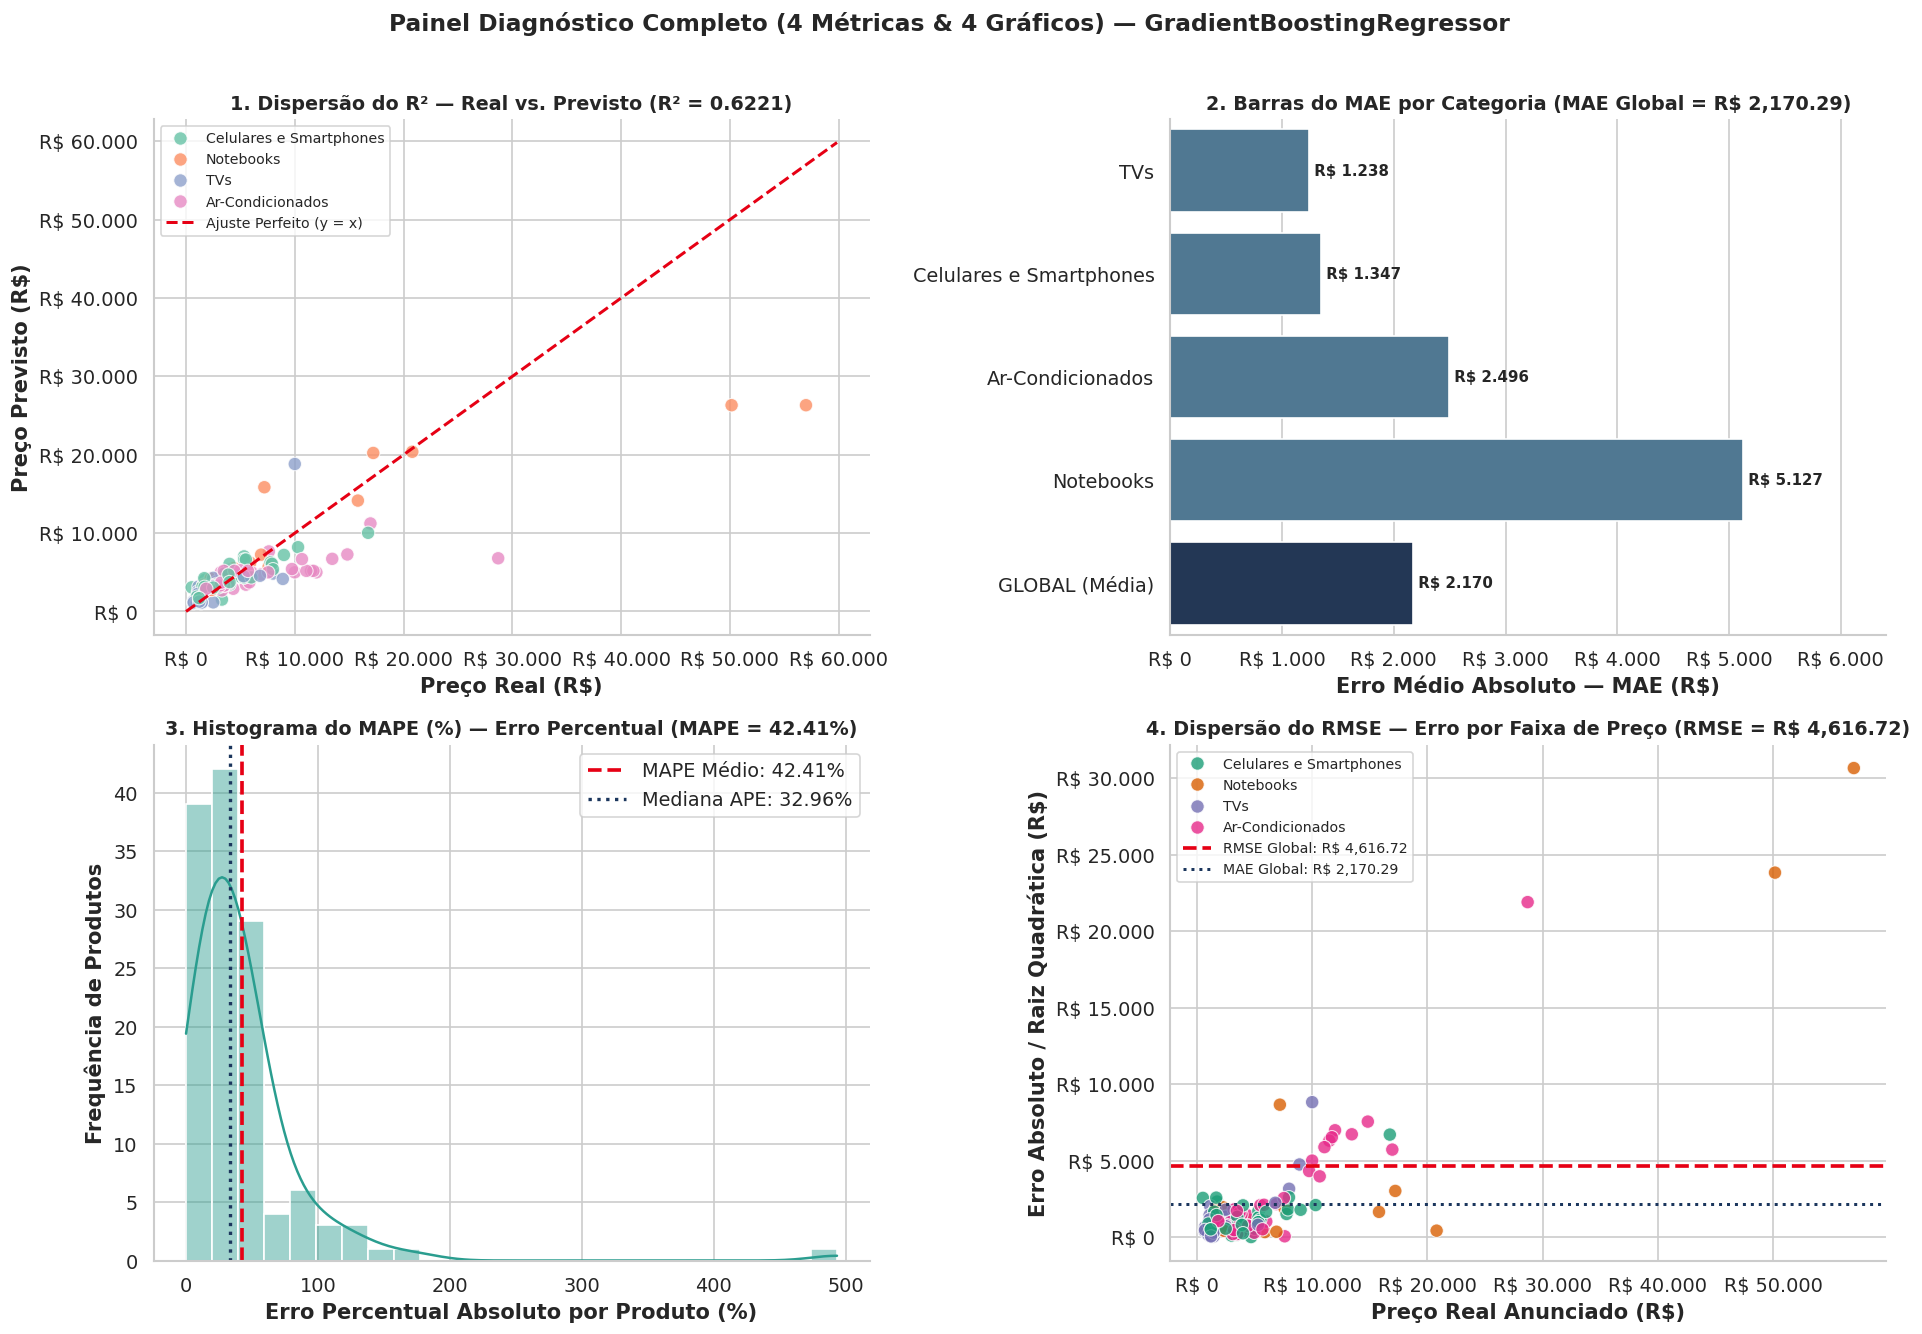


=== TABELA COMPARATIVA FINAL DOS 5 ALGORITMOS (ORDENADA POR R²) ===


,Modelo,MAE (R$),RMSE (R$),MAPE (%),R²
0,Árvore de Decisão,1840.04,4211.56,26.65,0.6855
1,KNeighborsRegressor,1918.76,4491.34,34.52,0.6424
2,GradientBoostingRegressor,2170.29,4616.72,42.41,0.6221
3,RandomForestRegressor,1934.76,4819.82,32.48,0.5881
4,Regressão Linear,2889.45,5830.16,75.62,0.3974


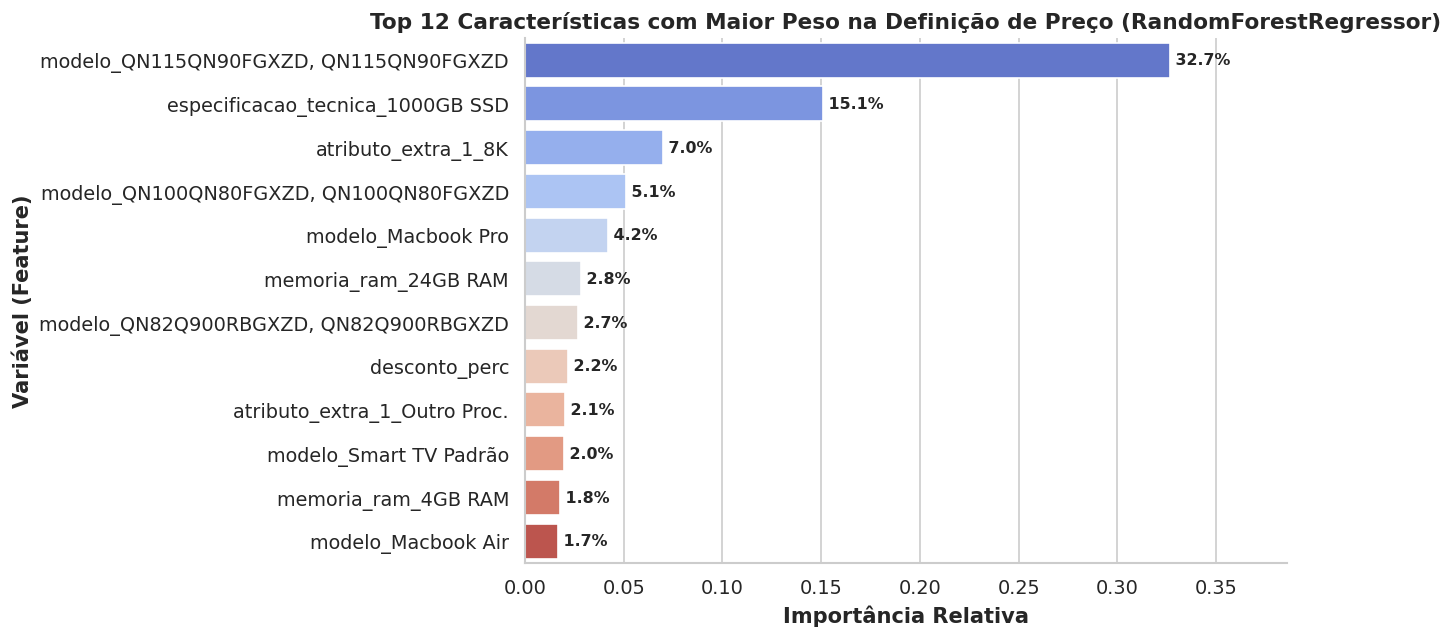

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# 1. Preparação das features e prevenção de Data Leakage
top_15_lojas = df['loja'].value_counts().head(15).index
df['loja_agrupada'] = df['loja'].where(df['loja'].isin(top_15_lojas), 'Outras')

features_num_geral = ['qtd_parcelas', 'desconto_perc', 'qtd_especificacoes_site']
features_cat_geral = [
    'categoria', 'marca', 'modelo', 'especificacao_tecnica', 'memoria_ram',
    'atributo_extra_1', 'atributo_extra_2', 'voltagem', 'tem_juros', 'seller_terceiro', 'loja_agrupada'
]

X_geral = df[features_num_geral + features_cat_geral].copy()
y_geral = df['preco_vista'].copy()

X_geral_enc = pd.get_dummies(X_geral, columns=features_cat_geral, drop_first=True)

# 2. Divisão Treino e Teste (80/20 com random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X_geral_enc, y_geral, test_size=0.20, random_state=42
)
categorias_teste = df.loc[y_test.index, 'categoria'].values

# 3. Normalização com RobustScaler (fit APENAS no treino para evitar Data Leakage)
scaler_geral = RobustScaler()
X_train[features_num_geral] = scaler_geral.fit_transform(X_train[features_num_geral])
X_test[features_num_geral] = scaler_geral.transform(X_test[features_num_geral])

# 4. Lista com os 5 algoritmos obrigatórios
lista_modelos = [
    ("Regressão Linear", LinearRegression()),
    ("Árvore de Decisão", DecisionTreeRegressor(random_state=42)),
    ("KNeighborsRegressor", KNeighborsRegressor(n_neighbors=5, weights="distance", n_jobs=-1)),
    ("RandomForestRegressor", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ("GradientBoostingRegressor", GradientBoostingRegressor(n_estimators=200, learning_rate=0.08, random_state=42))
]

res_gerais = []
modelos_treinados_dict = {}

# 5. Estrutura de repetição (for) para treinar, avaliar e plotar os 4 gráficos de CADA modelo
for nome_modelo, modelo in lista_modelos:
    print("=" * 95)
    print(f"🚀 EXECUTANDO ALGORITMO: {nome_modelo.upper()}")
    print("=" * 95)

    # 5.1 Treinamento com os dados de treino (X_train, y_train)
    modelo.fit(X_train, y_train)
    modelos_treinados_dict[nome_modelo] = modelo

    # 5.2 Predição utilizando os dados de teste (X_test)
    y_pred = np.maximum(modelo.predict(X_test), 0)

    # 5.3 Cálculo e impressão das 4 métricas de negócio (MAE, RMSE, MAPE e R²)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)

    print(f"📊 Métricas de Negócio ({nome_modelo}):")
    print(f"   • MAE  (Erro Médio Absoluto):            R$ {mae:,.2f}")
    print(f"   • RMSE (Raiz do Erro Quadrático Médio):  R$ {rmse:,.2f}")
    print(f"   • MAPE (Erro Percentual Médio Absoluto): {mape:.2f}%")
    print(f"   • R²   (Coeficiente de Determinação):    {r2:.4f} ({r2*100:.2f}% de variância explicada)")

    res_gerais.append({
        "Modelo": nome_modelo,
        "MAE (R$)": round(mae, 2),
        "RMSE (R$)": round(rmse, 2),
        "MAPE (%)": round(mape, 2),
        "R²": round(r2, 4)
    })

    # Vetores auxiliares por amostra de teste para os 4 gráficos específicos do modelo
    erros_abs = np.abs(y_test.values - y_pred)
    erros_perc = (erros_abs / np.maximum(y_test.values, 1e-6)) * 100
    erros_quad_raiz = np.sqrt((y_test.values - y_pred) ** 2)

    df_eval_amostra = pd.DataFrame({
        "Categoria": categorias_teste,
        "Real": y_test.values,
        "Previsto": y_pred,
        "Erro_Abs": erros_abs,
        "MAPE_Amostra": erros_perc,
        "RMSE_Amostra": erros_quad_raiz
    })

    # 5.4 Geração e exibição dos 4 gráficos de avaliação obrigatórios para ESTE modelo específico
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))

    # Gráfico 1: Dispersão do R² (Preço Real vs. Preço Previsto)
    ax1 = axes[0, 0]
    sns.scatterplot(x="Real", y="Previsto", hue="Categoria", data=df_eval_amostra, alpha=0.8, s=65, palette="Set2", ax=ax1)
    lim_max = max(y_test.max(), y_pred.max()) * 1.05
    ax1.plot([0, lim_max], [0, lim_max], color="#E60014", linestyle="--", linewidth=1.8, label="Ajuste Perfeito (y = x)")
    ax1.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax1.yaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax1.set_title(f"1. Dispersão do R² — Real vs. Previsto (R² = {r2:.4f})", fontsize=11.5, fontweight="bold")
    ax1.set_xlabel("Preço Real (R$)")
    ax1.set_ylabel("Preço Previsto (R$)")
    ax1.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white")

    # Gráfico 2: Barras do MAE (Erro Médio Absoluto em R$ por Categoria + Global)
    ax2 = axes[0, 1]
    mae_por_cat = df_eval_amostra.groupby("Categoria")["Erro_Abs"].mean().sort_values(ascending=True)
    mae_por_cat["GLOBAL (Média)"] = mae
    cores_mae = ["#457B9D"] * (len(mae_por_cat) - 1) + ["#1B365D"]
    sns.barplot(x=mae_por_cat.values, y=mae_por_cat.index, hue=mae_por_cat.index, palette=cores_mae, legend=False, ax=ax2)
    for p in ax2.patches:
        w = p.get_width()
        if w > 0:
            ax2.text(w, p.get_y() + p.get_height() / 2, f" R$ {w:,.0f}".replace(",", "."), va="center", ha="left", fontsize=9, fontweight="bold")
    ax2.set_xlim(0, mae_por_cat.values.max() * 1.25)
    ax2.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax2.set_title(f"2. Barras do MAE por Categoria (MAE Global = R$ {mae:,.2f})", fontsize=11.5, fontweight="bold")
    ax2.set_xlabel("Erro Médio Absoluto — MAE (R$)")
    ax2.set_ylabel("")

    # Gráfico 3: Histograma do MAPE (%) (Distribuição do Erro Percentual)
    ax3 = axes[1, 0]
    sns.histplot(df_eval_amostra["MAPE_Amostra"], bins=25, kde=True, color="#2A9D8F", alpha=0.45, edgecolor="white", ax=ax3)
    ax3.axvline(mape, color="#E60014", linestyle="--", linewidth=2.2, label=f"MAPE Médio: {mape:.2f}%")
    ax3.axvline(df_eval_amostra["MAPE_Amostra"].median(), color="#1B365D", linestyle=":", linewidth=2.0, label=f"Mediana APE: {df_eval_amostra['MAPE_Amostra'].median():.2f}%")
    ax3.set_title(f"3. Histograma do MAPE (%) — Erro Percentual (MAPE = {mape:.2f}%)", fontsize=11.5, fontweight="bold")
    ax3.set_xlabel("Erro Percentual Absoluto por Produto (%)")
    ax3.set_ylabel("Frequência de Produtos")
    ax3.legend(frameon=True, facecolor="white")

    # Gráfico 4: Dispersão do RMSE (Magnitude do Erro Individual vs. Preço Real)
    ax4 = axes[1, 1]
    sns.scatterplot(x="Real", y="RMSE_Amostra", hue="Categoria", data=df_eval_amostra, alpha=0.8, s=65, palette="Dark2", ax=ax4)
    ax4.axhline(rmse, color="#E60014", linestyle="--", linewidth=2.2, label=f"RMSE Global: R$ {rmse:,.2f}")
    ax4.axhline(mae, color="#1B365D", linestyle=":", linewidth=1.8, label=f"MAE Global: R$ {mae:,.2f}")
    ax4.xaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax4.yaxis.set_major_formatter(mtick.FuncFormatter(formatar_reais))
    ax4.set_title(f"4. Dispersão do RMSE — Erro por Faixa de Preço (RMSE = R$ {rmse:,.2f})", fontsize=11.5, fontweight="bold")
    ax4.set_xlabel("Preço Real Anunciado (R$)")
    ax4.set_ylabel("Erro Absoluto / Raiz Quadrática (R$)")
    ax4.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white")

    plt.suptitle(f"Painel Diagnóstico Completo (4 Métricas & 4 Gráficos) — {nome_modelo}", fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

# Tabela Consolidada Comparando os 5 Algoritmos
df_metricas_gerais = pd.DataFrame(res_gerais).sort_values(by="R²", ascending=False).reset_index(drop=True)
print("\n=== TABELA COMPARATIVA FINAL DOS 5 ALGORITMOS (ORDENADA POR R²) ===")
display(df_metricas_gerais)

# Feature Importance do RandomForestRegressor (Top 12 variáveis que mais explicam o preço)
rf_geral = modelos_treinados_dict["RandomForestRegressor"]
importancias = pd.Series(rf_geral.feature_importances_, index=X_geral_enc.columns).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(x=importancias.values, y=importancias.index, hue=importancias.index, palette="coolwarm", legend=False, ax=ax)
for p in ax.patches:
    w = p.get_width()
    if w > 0:
        ax.text(w, p.get_y() + p.get_height() / 2, f" {w*100:.1f}%", va="center", ha="left", fontsize=9.5, fontweight="bold")
ax.set_xlim(0, importancias.values.max() * 1.18)
ax.set_title("Top 12 Características com Maior Peso na Definição de Preço (RandomForestRegressor)", fontsize=13, fontweight="bold")
ax.set_xlabel("Importância Relativa")
ax.set_ylabel("Variável (Feature)")
plt.tight_layout()
plt.show()


In [13]:
import json
import pandas as pd

# 1. Preparação dos dados consolidados para o dashboard
# KPIs
total_produtos = len(df)
ticket_medio = df['preco_vista'].mean()
preco_maximo = df['preco_vista'].max()
desconto_medio = df['desconto_perc'].mean()

# Distribuição por Categoria
cat_counts = df['categoria'].value_counts().to_dict()
cat_prices = df.groupby('categoria')['preco_vista'].mean().round(2).to_dict()

# Top Marcas
top_marcas_dict = df['marca'].value_counts().head(10).to_dict()

# Top Lojas
top_lojas_dict = df['loja'].value_counts().head(10).to_dict()

# Amostra de Produtos para a Tabela HTML (primeiros 100 para não estourar tamanho do arquivo)
produtos_lista = df[['categoria', 'marca', 'modelo', 'preco_vista', 'desconto_perc', 'loja']].head(100).to_dict(orient='records')

# 2. Template HTML Integrado com Bootstrap, Tailwind, Chart.js e FontAwesome
html_content = f"""<!DOCTYPE html>
<html lang="pt-BR">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>BI Dashboard - Análise Preditiva Americanas</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.4.0/css/all.min.css">
</head>
<body class="bg-gray-900 text-gray-100 min-h-screen font-sans">

    <!-- Sidebar / Top Header -->
    <div class="flex flex-col md:flex-row">
        <div class="w-full md:w-64 bg-gray-800 p-6 flex flex-col justify-between border-b md:border-b-0 md:border-r border-gray-700 min-h-screen">
            <div>
                <div class="flex items-center space-x-3 mb-8">
                    <i class="fa-solid fa-chart-line text-red-500 text-3xl"></i>
                    <span class="text-xl font-bold tracking-wider">BI Americanas</span>
                </div>
                <nav class="space-y-4">
                    <a href="#" class="flex items-center space-x-3 text-red-500 bg-gray-700 p-3 rounded-lg font-semibold">
                        <i class="fa-solid fa-gauge"></i>
                        <span>Dashboard</span>
                    </a>
                    <a href="#tabela-dados" class="flex items-center space-x-3 text-gray-400 hover:text-white p-3 rounded-lg transition">
                        <i class="fa-solid fa-table"></i>
                        <span>Tabela de Dados</span>
                    </a>
                </nav>
            </div>
            <div class="text-xs text-gray-500 border-t border-gray-700 pt-4">
                Desenvolvido por Equipe IA &bull; 2025
            </div>
        </div>

        <!-- Main Content -->
        <main class="flex-1 p-6 md:p-10 space-y-8">
            <!-- Header -->
            <div class="flex flex-col md:flex-row md:items-center md:justify-between space-y-4 md:space-y-0">
                <div>
                    <h1 class="text-3xl font-bold">Painel de Gestão de E-commerce</h1>
                    <p class="text-gray-400">Análise Preditiva e Indicadores de Precificação Dinâmica</p>
                </div>
                <div class="flex space-x-3">
                    <button onclick="window.print()" class="bg-red-600 hover:bg-red-700 text-white px-4 py-2.5 rounded-lg flex items-center space-x-2 transition font-semibold">
                        <i class="fa-solid fa-file-pdf"></i>
                        <span>Exportar Relatório</span>
                    </button>
                </div>
            </div>

            <!-- Cards de KPIs -->
            <div class="grid grid-cols-1 md:grid-cols-2 lg:grid-cols-4 gap-6">
                <!-- KPI 1 -->
                <div class="bg-gray-800 p-6 rounded-2xl border border-gray-700 flex items-center justify-between">
                    <div>
                        <p class="text-sm text-gray-400 font-semibold">Total de Aparelhos</p>
                        <h3 class="text-2xl font-bold mt-1">{total_produtos}</h3>
                    </div>
                    <div class="bg-red-950 p-4 rounded-xl text-red-500">
                        <i class="fa-solid fa-box-open text-2xl"></i>
                    </div>
                </div>
                <!-- KPI 2 -->
                <div class="bg-gray-800 p-6 rounded-2xl border border-gray-700 flex items-center justify-between">
                    <div>
                        <p class="text-sm text-gray-400 font-semibold">Ticket Médio</p>
                        <h3 class="text-2xl font-bold mt-1">R$ {ticket_medio:,.2f}</h3>
                    </div>
                    <div class="bg-green-950 p-4 rounded-xl text-green-500">
                        <i class="fa-solid fa-hand-holding-dollar text-2xl"></i>
                    </div>
                </div>
                <!-- KPI 3 -->
                <div class="bg-gray-800 p-6 rounded-2xl border border-gray-700 flex items-center justify-between">
                    <div>
                        <p class="text-sm text-gray-400 font-semibold">Preço Máximo</p>
                        <h3 class="text-2xl font-bold mt-1">R$ {preco_maximo:,.2f}</h3>
                    </div>
                    <div class="bg-blue-950 p-4 rounded-xl text-blue-500">
                        <i class="fa-solid fa-tags text-2xl"></i>
                    </div>
                </div>
                <!-- KPI 4 -->
                <div class="bg-gray-800 p-6 rounded-2xl border border-gray-700 flex items-center justify-between">
                    <div>
                        <p class="text-sm text-gray-400 font-semibold">Desconto Médio</p>
                        <h3 class="text-2xl font-bold mt-1">{desconto_medio:.2f}%</h3>
                    </div>
                    <div class="bg-amber-950 p-4 rounded-xl text-amber-500">
                        <i class="fa-solid fa-percent text-2xl"></i>
                    </div>
                </div>
            </div>

            <!-- Seção de Gráficos -->
            <div class="grid grid-cols-1 lg:grid-cols-2 gap-8">
                <!-- Gráfico 1 -->
                <div class="bg-gray-800 p-6 rounded-2xl border border-gray-700">
                    <h3 class="text-lg font-semibold mb-4"><i class="fa-solid fa-chart-pie text-red-500 mr-2"></i>Distribuição por Categoria</h3>
                    <div class="relative h-80">
                        <canvas id="chartCategoria"></canvas>
                    </div>
                </div>
                <!-- Gráfico 2 -->
                <div class="bg-gray-800 p-6 rounded-2xl border border-gray-700">
                    <h3 class="text-lg font-semibold mb-4"><i class="fa-solid fa-ranking-star text-red-500 mr-2"></i>Top Marcas (Presença)</h3>
                    <div class="relative h-80">
                        <canvas id="chartMarcas"></canvas>
                    </div>
                </div>
            </div>

            <!-- Tabela Detalhada -->
            <div id="tabela-dados" class="bg-gray-800 p-6 rounded-2xl border border-gray-700">
                <div class="flex flex-col md:flex-row md:items-center md:justify-between mb-6 space-y-4 md:space-y-0">
                    <h3 class="text-lg font-semibold"><i class="fa-solid fa-list text-red-500 mr-2"></i>Catálogo de Monitoramento</h3>
                    <input type="text" id="pesquisaTab" placeholder="Buscar por marca, modelo, categoria..." class="bg-gray-700 text-gray-100 placeholder-gray-400 px-4 py-2 rounded-lg focus:outline-none focus:ring-2 focus:ring-red-500 w-full md:w-80 border border-gray-600">
                </div>
                <div class="overflow-x-auto">
                    <table class="min-w-full divide-y divide-gray-700">
                        <thead class="bg-gray-700">
                            <tr>
                                <th class="px-6 py-3 text-left text-xs font-semibold uppercase tracking-wider text-gray-300">Categoria</th>
                                <th class="px-6 py-3 text-left text-xs font-semibold uppercase tracking-wider text-gray-300">Marca</th>
                                <th class="px-6 py-3 text-left text-xs font-semibold uppercase tracking-wider text-gray-300">Modelo</th>
                                <th class="px-6 py-3 text-left text-xs font-semibold uppercase tracking-wider text-gray-300">Preço à Vista</th>
                                <th class="px-6 py-3 text-left text-xs font-semibold uppercase tracking-wider text-gray-300">Desconto (%)</th>
                                <th class="px-6 py-3 text-left text-xs font-semibold uppercase tracking-wider text-gray-300">Loja</th>
                            </tr>
                        </thead>
                        <tbody id="corpoTabela" class="divide-y divide-gray-700 bg-gray-800/50">
                            <!-- Preenchido via JavaScript -->
                        </tbody>
                    </table>
                </div>
            </div>
        </main>
    </div>

    <!-- Scripts para Gráficos e Lógica da Tabela -->
    <script>
        // Dados transferidos do Python
        const catCounts = {json.dumps(cat_counts)};
        const topMarcas = {json.dumps(top_marcas_dict)};
        const produtos = {json.dumps(produtos_lista)};

        // Gráfico Categoria
        new Chart(document.getElementById('chartCategoria'), {{
            type: 'doughnut',
            data: {{
                labels: Object.keys(catCounts),
                datasets: [[
                    data: Object.values(catCounts),
                    backgroundColor: ['#ef4444', '#10b981', '#3b82f6', '#f59e0b'],
                    borderWidth: 0
                ]]
            }},
            options: {{
                responsive: true,
                maintainAspectRatio: false,
                plugins: {{
                    legend: {{
                        position: 'bottom',
                        labels: {{ color: '#fff' }}
                    }}
                }}
            }}
        }});

        // Gráfico de Marcas
        new Chart(document.getElementById('chartMarcas'), {{
            type: 'bar',
            data: {{
                labels: Object.keys(topMarcas),
                datasets: [[
                    label: 'Quantidade de Ofertas',
                    data: Object.values(topMarcas),
                    backgroundColor: '#3b82f6'
                ]]
            }},
            options: {{
                responsive: true,
                maintainAspectRatio: false,
                plugins: {{
                    legend: {{ display: false }}
                }},
                scales: {{
                    x: {{ ticks: {{ color: '#fff' }} }},
                    y: {{ ticks: {{ color: '#fff' }} }}
                }}
            }}
        }});

        // Preenchimento e Filtro da Tabela
        const corpo = document.getElementById('corpoTabela');
        const inputPesquisa = document.getElementById('pesquisaTab');

        function renderTable(data) {{
            corpo.innerHTML = '';
            data.forEach(p => {{
                const tr = document.createElement('tr');
                tr.innerHTML = `
                    <td class="px-6 py-4 text-sm font-medium">${{p.categoria}}</td>
                    <td class="px-6 py-4 text-sm text-gray-300">${{p.marca}}</td>
                    <td class="px-6 py-4 text-sm text-gray-300">${{p.modelo}}</td>
                    <td class="px-6 py-4 text-sm font-semibold text-green-400">R$ ${{p.preco_vista.toLocaleString('pt-BR', {{minimumFractionDigits: 2}})}}</td>
                    <td class="px-6 py-4 text-sm text-gray-300">${{p.desconto_perc}}%</td>
                    <td class="px-6 py-4 text-sm text-gray-400">${{p.loja}}</td>
                `;
                corpo.appendChild(tr);
            }});
        }}

        inputPesquisa.addEventListener('input', (e) => {{
            const query = e.target.value.toLowerCase();
            const filtered = produtos.filter(p =>
                p.categoria.toLowerCase().includes(query) ||
                p.marca.toLowerCase().includes(query) ||
                p.modelo.toLowerCase().includes(query) ||
                p.loja.toLowerCase().includes(query)
            );
            renderTable(filtered);
        }});

        renderTable(produtos);
    </script>
</body>
</html>
"""

# Escreve o arquivo HTML no diretório do Colab
with open("painel_gestao_bi.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("✅ Dashboard interativo 'painel_gestao_bi.html' gerado com sucesso!")

# Disponibiliza link de download se estiver no ambiente Colab
if "google.colab" in sys.modules:
    from google.colab import files
    files.download("painel_gestao_bi.html")

✅ Dashboard interativo 'painel_gestao_bi.html' gerado com sucesso!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusão e Interpretação dos Modelos Preditivos (Etapa 3)
* **Regressões Lineares por Categoria:** O treinamento individualizado por categoria isola a dinâmica de precificação de cada segmento (**Ar-Condicionados**, **TVs**, **Notebooks** e **Celulares e Smartphones**). O **MAE** indica o erro médio direto em Reais (R$) na previsão do preço à vista nos dados de teste.
* **Comparação Consolidada:** O **Random Forest Regressor** complementa a Regressão Linear ao capturar interações não lineares entre marca, modelo e especificação técnica, absorvendo melhor os *outliers* superiores identificados nos boxplots.
* **Principais Direcionadores de Preço:** A **categoria do aparelho**, a **especificação técnica principal** (BTUs, polegadas e armazenamento SSD/GB) e a **marca** exercem o maior peso na definição do preço, permitindo ao gestor de e-commerce auditar anúncios desalinhados com o mercado.


---
## Exportação dos Relatórios para Entrega (Consolidado + Por Categoria)

A célula abaixo gera e exporta:
1. **`base_americanas_consolidada.csv`** — Base completa tratada com **todas as marcas e todas as especificações do site** (arquivo obrigatório para entrega).
2. **`relatorio_ar_condicionados.csv`** — Relatório CSV exclusivo de **Ar-Condicionados**.
3. **`relatorio_tvs.csv`** — Relatório CSV exclusivo de **TVs**.
4. **`relatorio_notebooks.csv`** — Relatório CSV exclusivo de **Notebooks**.
5. **`relatorio_celulares_smartphones.csv`** — Relatório CSV exclusivo de **Celulares e Smartphones**.
6. **`relatorio_americanas_por_categoria.xlsx`** — Planilha Excel com **abas separadas para cada categoria**, aba **Consolidado**, aba **Resumo_Precos**, aba **Diagnostico_Outliers** e aba **Metricas_Regressao_Linear**.
7. **`todos_relatorios_americanas.zip`** — Pacote único contendo todos os 5 CSVs + a planilha Excel.


In [12]:
# 1. Exporta CSV consolidado (exigido na entrega)
arquivo_csv_consolidado = "base_americanas_consolidada.csv"
df.to_csv(arquivo_csv_consolidado, index=False, encoding="utf-8-sig")
print(f"✅ 1/5 CSV Consolidado gerado: {arquivo_csv_consolidado} ({len(df)} registros)")

# 2. Exporta os 4 CSVs individuais por categoria (com todas as marcas e especificações do site)
arquivos_csv_categorias = {
    "Ar-Condicionados": "relatorio_ar_condicionados.csv",
    "TVs": "relatorio_tvs.csv",
    "Notebooks": "relatorio_notebooks.csv",
    "Celulares e Smartphones": "relatorio_celulares_smartphones.csv"
}

lista_arquivos_gerados = [arquivo_csv_consolidado]

for idx, (nome_cat, nome_csv) in enumerate(arquivos_csv_categorias.items(), start=2):
    df_cat = df[df["categoria"] == nome_cat].sort_values(by=["marca", "especificacao_tecnica", "preco_vista"])
    df_cat.to_csv(nome_csv, index=False, encoding="utf-8-sig")
    lista_arquivos_gerados.append(nome_csv)
    print(f"✅ {idx}/5 CSV por Categoria gerado: {nome_csv} ({len(df_cat)} registros)")

# 3. Gera planilha Excel (.xlsx) com abas por categoria + Resumo + Outliers + Métricas das Regressões Lineares
arquivo_excel = "relatorio_americanas_por_categoria.xlsx"

abas_excel = {
    "Ar-Condicionados": "Ar-Condicionados",
    "TVs": "TVs",
    "Notebooks": "Notebooks",
    "Celulares_Smartphones": "Celulares e Smartphones"
}

with pd.ExcelWriter(arquivo_excel, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Consolidado", index=False)

    for nome_aba, nome_cat in abas_excel.items():
        df_aba = df[df["categoria"] == nome_cat].sort_values(by=["marca", "especificacao_tecnica", "preco_vista"])
        df_aba.to_excel(writer, sheet_name=nome_aba, index=False)

    resumo_geral = (
        df.groupby(["categoria", "marca", "modelo", "perfil_tecnico", "voltagem"])["preco_vista"]
        .agg(
            Qtd_Ofertas="count",
            Preco_Minimo="min",
            Preco_Mediana="median",
            Preco_Medio="mean",
            Preco_Maximo="max"
        )
        .round(2)
        .reset_index()
        .sort_values(by=["categoria", "Qtd_Ofertas", "Preco_Mediana"], ascending=[True, False, True])
    )
    resumo_geral.to_excel(writer, sheet_name="Resumo_Precos", index=False)
    df_outliers_resumo.to_excel(writer, sheet_name="Diagnostico_Outliers", index=False)
    df_resumo_lr_cats.to_excel(writer, sheet_name="Metricas_Regressao_Linear", index=False)
    df_metricas_gerais.to_excel(writer, sheet_name="Metricas_5_Algoritmos", index=False)

lista_arquivos_gerados.append(arquivo_excel)
print(f"✅ Planilha Excel gerada: {arquivo_excel}")

# 4. Empacota os 5 CSVs + Excel em um ZIP único para download limpo
arquivo_zip = "todos_relatorios_americanas.zip"
with zipfile.ZipFile(arquivo_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for arq in lista_arquivos_gerados:
        zf.write(arq)

print(f"📦 Pacote ZIP completo gerado: {arquivo_zip}")
print(f"📂 Diretório de saída: {os.getcwd()}")

if "google.colab" in sys.modules:
    from google.colab import files
    files.download(arquivo_csv_consolidado)
    files.download(arquivo_zip)
else:
    print("💡 Execução local (Windows/Linux): todos os 5 CSVs, o Excel e o ZIP foram salvos na pasta acima!")


✅ 1/5 CSV Consolidado gerado: base_americanas_consolidada.csv (643 registros)
✅ 2/5 CSV por Categoria gerado: relatorio_ar_condicionados.csv (184 registros)
✅ 3/5 CSV por Categoria gerado: relatorio_tvs.csv (171 registros)
✅ 4/5 CSV por Categoria gerado: relatorio_notebooks.csv (92 registros)
✅ 5/5 CSV por Categoria gerado: relatorio_celulares_smartphones.csv (196 registros)
✅ Planilha Excel gerada: relatorio_americanas_por_categoria.xlsx
📦 Pacote ZIP completo gerado: todos_relatorios_americanas.zip
📂 Diretório de saída: /content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>